# Deteksi Tuberkulosis (TB) dari Chest X-ray dengan CNN + Transfer Learning

> **Kelompok E** — Model Classification: CNN dengan Transfer Learning
>
> Notebook ini membangun model klasifikasi biner (Normal vs TB) menggunakan tiga arsitektur CNN pretrained (EfficientNetB0, ResNet50, VGG16), mengevaluasi dan membandingkan performanya, serta menganalisis domain shift antar dataset Mendeley dan Kaggle.

---

## 1. Setup & Konfigurasi

In [44]:
# ============================================================
# 1.1 Mount Google Drive (untuk akses dataset)
# ============================================================
import os
import sys

# Deteksi apakah berjalan di Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    print('Google Drive mounted successfully.')
else:
    print('Not running in Colab. Using local paths.')

Not running in Colab. Using local paths.


In [45]:
# ============================================================
# 1.2 Install library tambahan (jika diperlukan)
# ============================================================
import subprocess
import sys

import_to_pip = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn',
    'cv2': 'opencv-python',
    'sklearn': 'scikit-learn',
    'openpyxl': 'openpyxl',
    'tensorflow': 'tensorflow'
}

print('Memeriksa dependensi library...')
for lib_name, pip_name in import_to_pip.items():
    try:
        __import__(lib_name)
        print(f'  ✓ {lib_name} sudah terinstall.')
    except ImportError:
        print(f'  ✗ {lib_name} tidak ditemukan. Menginstall {pip_name}...')
        try:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_name])
            print(f'  ✓ {lib_name} berhasil diinstall.')
        except Exception as e:
            print(f'  ⚠ Gagal menginstall {pip_name} secara otomatis. Silakan jalankan: !pip install {pip_name}')
            print(f'  Detail error: {e}')

print('\nPemeriksaan dependensi selesai.')


Memeriksa dependensi library...
  ✓ numpy sudah terinstall.
  ✓ pandas sudah terinstall.
  ✓ matplotlib sudah terinstall.
  ✓ seaborn sudah terinstall.
  ✓ cv2 sudah terinstall.
  ✓ sklearn sudah terinstall.
  ✓ openpyxl sudah terinstall.
  ✓ tensorflow sudah terinstall.

Pemeriksaan dependensi selesai.


In [46]:
# ============================================================
# 1.3 Import Libraries
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import cv2
import json
import warnings
import random
from pathlib import Path
from collections import Counter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0, ResNet50, VGG16
from tensorflow.keras.applications.efficientnet import preprocess_input as efn_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.metrics import AUC, Precision, Recall
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc,
    precision_recall_curve, f1_score, accuracy_score
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings('ignore')
print('All libraries imported successfully.')

All libraries imported successfully.


In [47]:
# ============================================================
# 1.4 Konfigurasi Global
# ============================================================

# --- Random Seed ---
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)

# --- Model & Training ---
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS_STAGE1 = 15       # Feature extraction (frozen base)
EPOCHS_STAGE2 = 15       # Fine-tuning (unfreeze top layers)
LEARNING_RATE_STAGE1 = 1e-4
LEARNING_RATE_STAGE2 = 1e-5

# --- Arsitektur yang dibandingkan ---
ARCHITECTURES = ['EfficientNetB0', 'ResNet50', 'VGG16']

# --- Path ---
# Sesuaikan BASE_DIR dengan lokasi dataset Anda
if IN_COLAB:
    # Opsi 1: Dataset di Google Drive
    BASE_DIR = Path('/content/drive/MyDrive/Deteksi Tuberkulosis (TB)')
    # Opsi 2: Dataset di-upload langsung ke Colab (uncomment jika pakai ini)
    # BASE_DIR = Path('/content/Deteksi Tuberkulosis (TB)')
else:
    BASE_DIR = Path(r'c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)')

# Sub-directories
MENDELEY_DIR = BASE_DIR / 'Mendeley'
KAGGLE_DIR = BASE_DIR / 'Kaggle'
OUTPUT_DIR = BASE_DIR / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)

# --- Blur threshold ---
LAPLACIAN_THRESHOLD = 50

print(f'BASE_DIR: {BASE_DIR}')
print(f'BASE_DIR exists: {BASE_DIR.exists()}')
print(f'MENDELEY_DIR exists: {MENDELEY_DIR.exists()}')
print(f'KAGGLE_DIR exists: {KAGGLE_DIR.exists()}')

BASE_DIR: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)
BASE_DIR exists: True
MENDELEY_DIR exists: True
KAGGLE_DIR exists: True


In [48]:
# ============================================================
# 1.5 Checkpoint: Versi Library & GPU
# ============================================================
print('=' * 60)
print('ENVIRONMENT INFO')
print('=' * 60)
print(f'Python       : {sys.version}')
print(f'TensorFlow   : {tf.__version__}')
print(f'Keras        : {keras.__version__}')
print(f'NumPy        : {np.__version__}')
print(f'Pandas       : {pd.__version__}')
print(f'OpenCV       : {cv2.__version__}')
print(f'Seed         : {RANDOM_SEED}')
print(f'Image Size   : {IMG_SIZE}')
print(f'Batch Size   : {BATCH_SIZE}')
print('-' * 60)

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'GPU tersedia : {len(gpus)} device(s)')
    for gpu in gpus:
        print(f'  - {gpu.name}')
    # Memory growth agar tidak alokasi semua VRAM sekaligus
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print('GPU tersedia : TIDAK ADA (menggunakan CPU)')
    print('  ⚠ Training akan sangat lambat tanpa GPU!')
print('=' * 60)

ENVIRONMENT INFO
Python       : 3.13.7 | packaged by Anaconda, Inc. | (main, Sep  9 2025, 19:54:37) [MSC v.1929 64 bit (AMD64)]
TensorFlow   : 2.21.0
Keras        : 3.14.1
NumPy        : 2.3.3
Pandas       : 2.3.2
OpenCV       : 4.13.0
Seed         : 42
Image Size   : (224, 224)
Batch Size   : 32
------------------------------------------------------------
GPU tersedia : TIDAK ADA (menggunakan CPU)
  ⚠ Training akan sangat lambat tanpa GPU!


---
## 2. Data Acquisition & Loading

In [49]:
# ============================================================
# 2.1 Definisi Path Dataset
# ============================================================

# Mendeley paths
MENDELEY_NORMAL_DIR = MENDELEY_DIR / 'Normal Chest X-rays'
MENDELEY_TB_DIR = MENDELEY_DIR / 'TB Chest X-rays'

# Kaggle paths
KAGGLE_NORMAL_DIR = KAGGLE_DIR / 'Normal'
KAGGLE_TB_DIR = KAGGLE_DIR / 'Tuberculosis'

# Kaggle metadata paths
KAGGLE_NORMAL_META = KAGGLE_DIR / 'Normal.metadata.xlsx'
KAGGLE_TB_META = KAGGLE_DIR / 'Tuberculosis.metadata.xlsx'

# Verifikasi semua path
paths_to_check = {
    'Mendeley Normal': MENDELEY_NORMAL_DIR,
    'Mendeley TB': MENDELEY_TB_DIR,
    'Kaggle Normal': KAGGLE_NORMAL_DIR,
    'Kaggle TB': KAGGLE_TB_DIR,
    'Kaggle Normal Metadata': KAGGLE_NORMAL_META,
    'Kaggle TB Metadata': KAGGLE_TB_META,
}

for name, path in paths_to_check.items():
    status = '✓' if path.exists() else '✗ NOT FOUND'
    print(f'  {status}  {name}: {path}')

  ✓  Mendeley Normal: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\Mendeley\Normal Chest X-rays
  ✓  Mendeley TB: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\Mendeley\TB Chest X-rays
  ✓  Kaggle Normal: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\Kaggle\Normal
  ✓  Kaggle TB: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\Kaggle\Tuberculosis
  ✓  Kaggle Normal Metadata: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\Kaggle\Normal.metadata.xlsx
  ✓  Kaggle TB Metadata: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\Kaggle\Tuberculosis.metadata.xlsx


In [50]:
# ============================================================
# 2.2 Baca Metadata Excel Kaggle (untuk sub_source)
# ============================================================

def read_kaggle_metadata(meta_path):
    """Baca metadata Excel Kaggle dan ekstrak sub_source dari URL."""
    df = pd.read_excel(meta_path, engine='openpyxl')
    
    # Map URL ke sub_source
    def url_to_subsource(url):
        if url is None:
            return 'unknown'
        url = str(url).lower()
        if 'tuberculosis.by' in url:
            return 'belarus'
        elif 'ncbi.nlm.nih.gov' in url:
            return 'nlm'
        elif 'rsna' in url or 'pneumonia' in url:
            return 'rsna'
        elif 'niaid' in url or 'tbportals' in url:
            return 'niaid'
        else:
            return 'other'
    
    df['sub_source'] = df['URL'].apply(url_to_subsource)
    # Buat mapping filename -> sub_source
    mapping = dict(zip(df['FILE NAME'], df['sub_source']))
    return mapping

# Baca metadata
kaggle_normal_subsource = read_kaggle_metadata(KAGGLE_NORMAL_META)
kaggle_tb_subsource = read_kaggle_metadata(KAGGLE_TB_META)

print('Kaggle Normal sub-source distribution:')
print(pd.Series(kaggle_normal_subsource.values()).value_counts().to_string())
print()
print('Kaggle TB sub-source distribution:')
print(pd.Series(kaggle_tb_subsource.values()).value_counts().to_string())

Kaggle Normal sub-source distribution:
rsna    3094
nlm      406

Kaggle TB sub-source distribution:
nlm        394
belarus    306


In [51]:
# ============================================================
# 2.3 Build Dataframe Metadata
# ============================================================

def build_metadata_df():
    """Scan semua gambar dan bangun dataframe metadata."""
    records = []
    
    # --- Mendeley Normal ---
    for fpath in sorted(MENDELEY_NORMAL_DIR.glob('*')):
        if fpath.suffix.lower() in ['.jpg', '.jpeg', '.png']:
            records.append({
                'filepath': str(fpath),
                'label': 'Normal',
                'source': 'mendeley',
                'sub_source': 'mendeley_single',
                'format': fpath.suffix.lower().replace('.', ''),
                'original_filename': fpath.name,
            })
    
    # --- Mendeley TB ---
    for fpath in sorted(MENDELEY_TB_DIR.glob('*')):
        if fpath.suffix.lower() in ['.jpg', '.jpeg', '.png']:
            records.append({
                'filepath': str(fpath),
                'label': 'TB',
                'source': 'mendeley',
                'sub_source': 'mendeley_single',
                'format': fpath.suffix.lower().replace('.', ''),
                'original_filename': fpath.name,
            })
    
    # --- Kaggle Normal ---
    for fpath in sorted(KAGGLE_NORMAL_DIR.glob('*')):
        if fpath.suffix.lower() in ['.jpg', '.jpeg', '.png']:
            fname_no_ext = fpath.stem  # e.g. 'Normal-1'
            sub_src = kaggle_normal_subsource.get(fname_no_ext, 'unknown')
            records.append({
                'filepath': str(fpath),
                'label': 'Normal',
                'source': 'kaggle',
                'sub_source': sub_src,
                'format': fpath.suffix.lower().replace('.', ''),
                'original_filename': fpath.name,
            })
    
    # --- Kaggle TB ---
    for fpath in sorted(KAGGLE_TB_DIR.glob('*')):
        if fpath.suffix.lower() in ['.jpg', '.jpeg', '.png']:
            fname_no_ext = fpath.stem  # e.g. 'Tuberculosis-1'
            sub_src = kaggle_tb_subsource.get(fname_no_ext, 'unknown')
            records.append({
                'filepath': str(fpath),
                'label': 'TB',
                'source': 'kaggle',
                'sub_source': sub_src,
                'format': fpath.suffix.lower().replace('.', ''),
                'original_filename': fpath.name,
            })
    
    df = pd.DataFrame(records)
    return df

df_raw = build_metadata_df()
print(f'Total gambar ditemukan: {len(df_raw)}')
print()
print('Distribusi per source × label:')
print(df_raw.groupby(['source', 'label']).size().unstack(fill_value=0))
print()
print('Distribusi per sub_source × label:')
print(df_raw.groupby(['sub_source', 'label']).size().unstack(fill_value=0))

Total gambar ditemukan: 7208

Distribusi per source × label:
label     Normal    TB
source                
kaggle      3500   700
mendeley     514  2494

Distribusi per sub_source × label:
label            Normal    TB
sub_source                   
belarus               0   306
mendeley_single     514  2494
nlm                 406   394
rsna               3094     0


In [52]:
# ============================================================
# 2.4 Baca Resolusi Gambar (width × height)
# ============================================================
# Ini membutuhkan waktu beberapa menit untuk ~7000 gambar

print('Membaca resolusi gambar... (ini mungkin memakan waktu beberapa menit)')

widths = []
heights = []
read_errors = []

for idx, row in df_raw.iterrows():
    img = cv2.imread(row['filepath'])
    if img is not None:
        h, w = img.shape[:2]
        widths.append(w)
        heights.append(h)
    else:
        widths.append(None)
        heights.append(None)
        read_errors.append(row['filepath'])
    
    if (idx + 1) % 1000 == 0:
        print(f'  Processed {idx + 1}/{len(df_raw)} gambar...')

df_raw['width'] = widths
df_raw['height'] = heights

print(f'\nSelesai. Gambar corrupt/tidak terbaca: {len(read_errors)}')
if read_errors:
    print('File bermasalah:')
    for f in read_errors[:10]:
        print(f'  - {f}')

Membaca resolusi gambar... (ini mungkin memakan waktu beberapa menit)
  Processed 1000/7208 gambar...
  Processed 2000/7208 gambar...
  Processed 3000/7208 gambar...
  Processed 4000/7208 gambar...
  Processed 5000/7208 gambar...
  Processed 6000/7208 gambar...
  Processed 7000/7208 gambar...

Selesai. Gambar corrupt/tidak terbaca: 0


In [53]:
# ============================================================
# 2.5 Checkpoint: Validasi Jumlah File
# ============================================================
print('=' * 60)
print('CHECKPOINT: Data Acquisition & Loading')
print('=' * 60)
print(f'Total gambar: {len(df_raw)}')
print(f'Gambar corrupt: {len(read_errors)}')
print()
print('Distribusi per source × label:')
dist = df_raw.groupby(['source', 'label']).size().unstack(fill_value=0)
dist['Total'] = dist.sum(axis=1)
dist.loc['Total'] = dist.sum()
print(dist.to_string())
print()
print('Distribusi per sub_source:')
sub_dist = df_raw.groupby(['sub_source', 'label']).size().unstack(fill_value=0)
sub_dist['Total'] = sub_dist.sum(axis=1)
print(sub_dist.to_string())
print('=' * 60)

CHECKPOINT: Data Acquisition & Loading
Total gambar: 7208
Gambar corrupt: 0

Distribusi per source × label:
label     Normal    TB  Total
source                       
kaggle      3500   700   4200
mendeley     514  2494   3008
Total       4014  3194   7208

Distribusi per sub_source:
label            Normal    TB  Total
sub_source                          
belarus               0   306    306
mendeley_single     514  2494   3008
nlm                 406   394    800
rsna               3094     0   3094


---
## 3. Exploratory Sanity Check

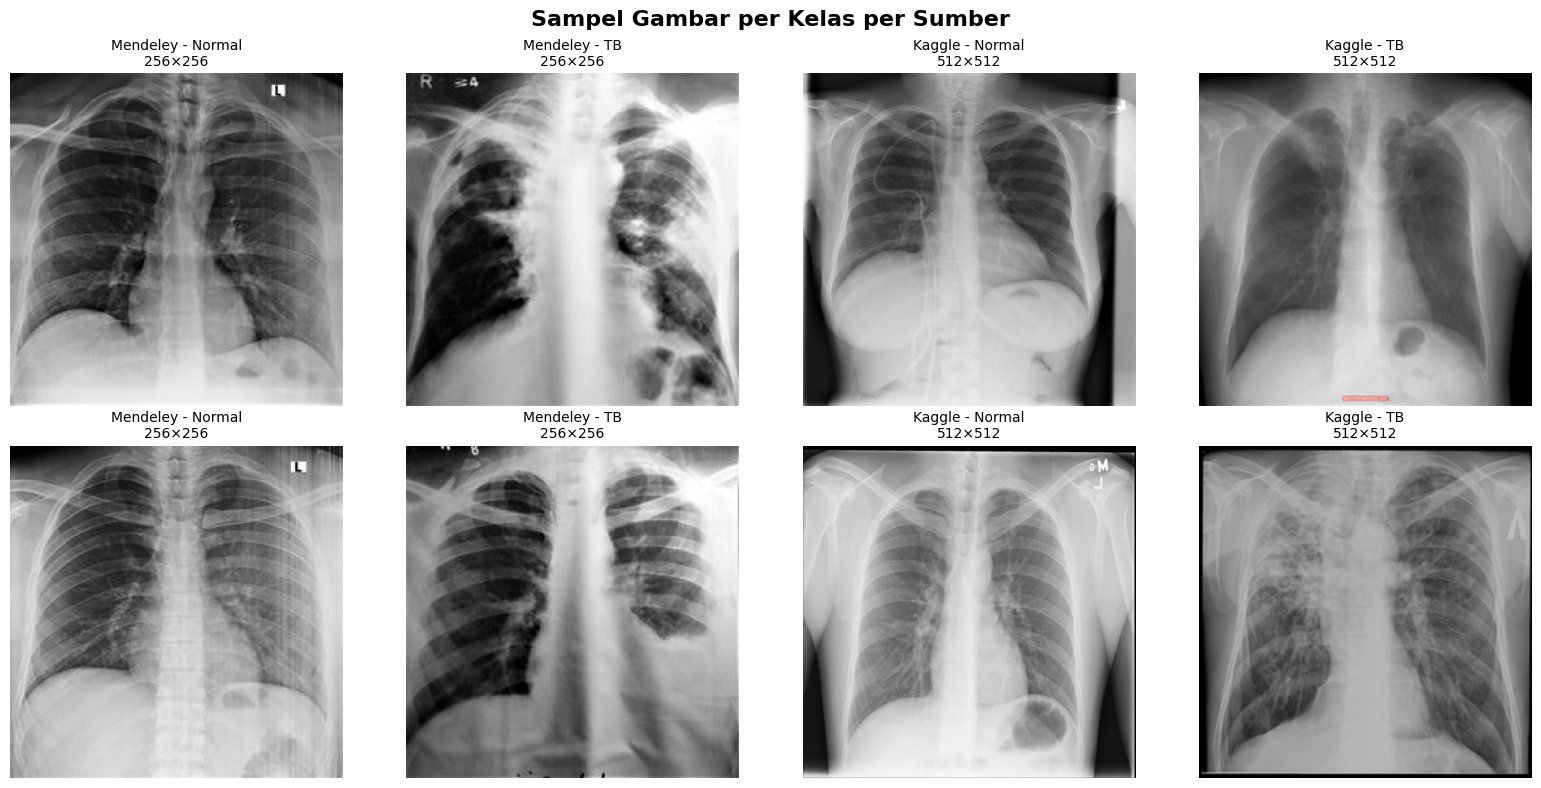

In [54]:
# ============================================================
# 3.1 Visualisasi Sampel Gambar per Kelas per Sumber
# ============================================================

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Sampel Gambar per Kelas per Sumber', fontsize=16, fontweight='bold')

combinations = [
    ('mendeley', 'Normal'), ('mendeley', 'TB'),
    ('kaggle', 'Normal'), ('kaggle', 'TB'),
]

for i, (source, label) in enumerate(combinations):
    subset = df_raw[(df_raw['source'] == source) & (df_raw['label'] == label)]
    samples = subset.sample(n=2, random_state=RANDOM_SEED)
    
    for j, (_, row) in enumerate(samples.iterrows()):
        ax = axes[j, i]
        img = cv2.imread(row['filepath'])
        if img is not None:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img_rgb, cmap='gray')
        ax.set_title(f"{source.capitalize()} - {label}\n{row['width']}×{row['height']}", fontsize=10)
        ax.axis('off')

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'sample_images.png'), dpi=150, bbox_inches='tight')
plt.show()

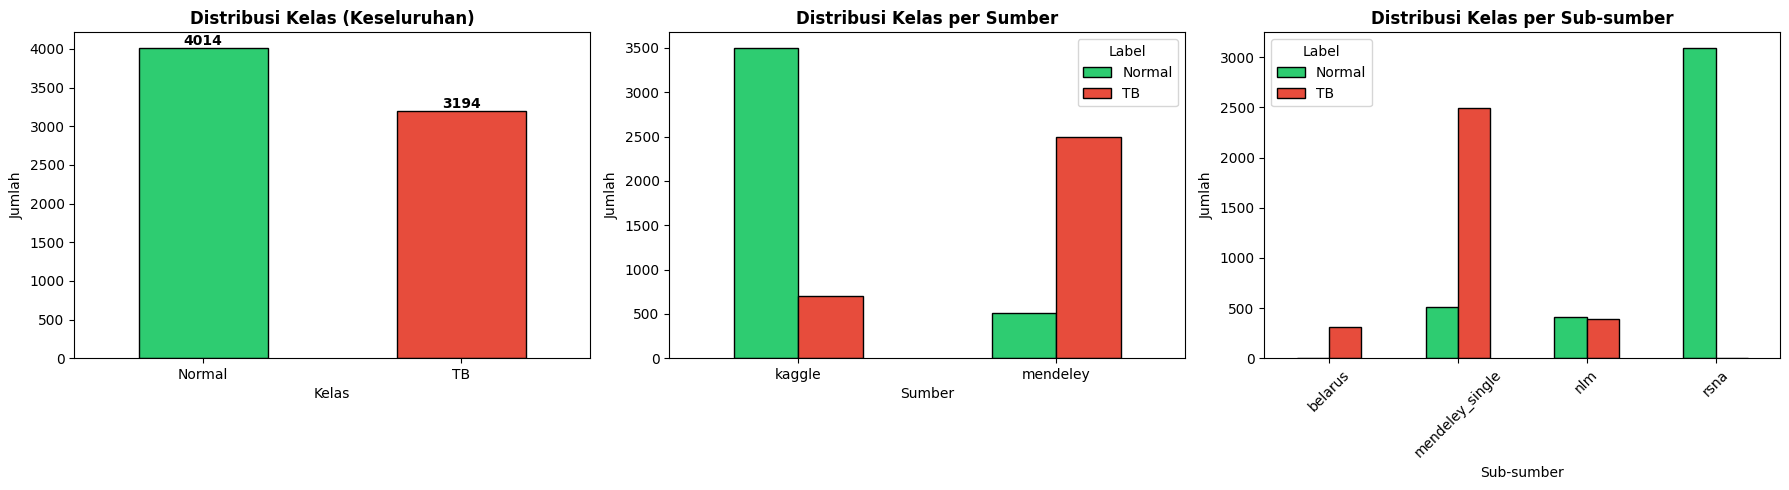

Rasio TB:Normal = 1:1.26


In [55]:
# ============================================================
# 3.2 Distribusi Kelas per Sumber (Bar Chart)
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Overall distribution
ax = axes[0]
df_raw['label'].value_counts().plot(kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'], edgecolor='black')
ax.set_title('Distribusi Kelas (Keseluruhan)', fontweight='bold')
ax.set_xlabel('Kelas')
ax.set_ylabel('Jumlah')
ax.tick_params(axis='x', rotation=0)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
               ha='center', va='bottom', fontweight='bold')

# Plot 2: Per source
ax = axes[1]
ct = df_raw.groupby(['source', 'label']).size().unstack(fill_value=0)
ct.plot(kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'], edgecolor='black')
ax.set_title('Distribusi Kelas per Sumber', fontweight='bold')
ax.set_xlabel('Sumber')
ax.set_ylabel('Jumlah')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Label')

# Plot 3: Per sub_source
ax = axes[2]
ct2 = df_raw.groupby(['sub_source', 'label']).size().unstack(fill_value=0)
ct2.plot(kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'], edgecolor='black')
ax.set_title('Distribusi Kelas per Sub-sumber', fontweight='bold')
ax.set_xlabel('Sub-sumber')
ax.set_ylabel('Jumlah')
ax.tick_params(axis='x', rotation=45)
ax.legend(title='Label')

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'class_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

# Rasio kelas
n_normal = (df_raw['label'] == 'Normal').sum()
n_tb = (df_raw['label'] == 'TB').sum()
print(f'Rasio TB:Normal = 1:{n_normal/n_tb:.2f}')

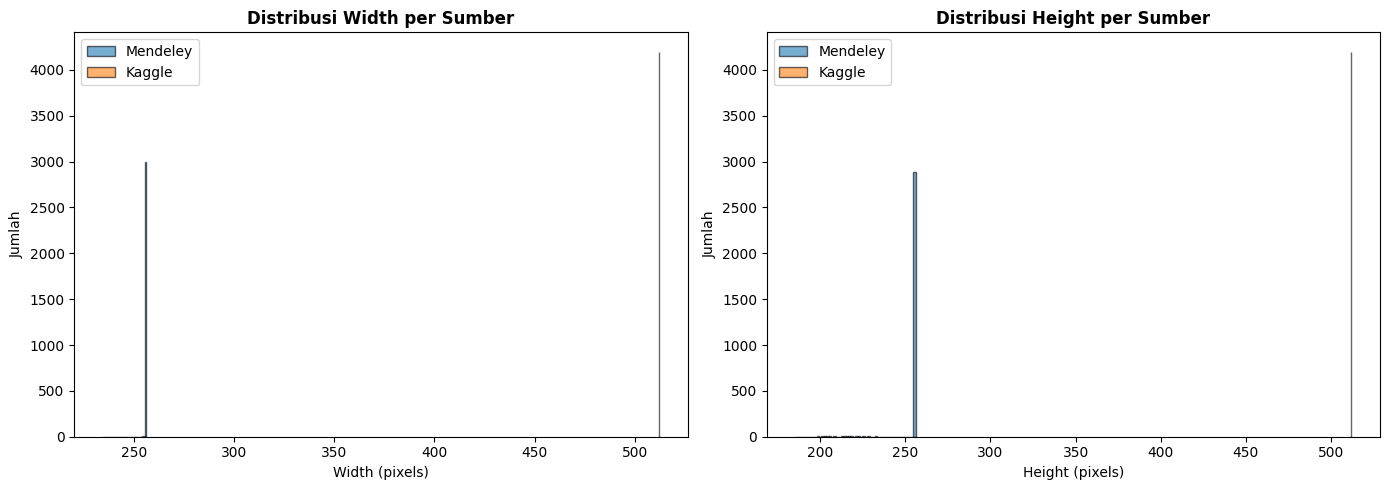

Statistik resolusi per sumber:
           width                                                           height                                                         
           count        mean       std    min    25%    50%    75%    max   count        mean       std    min    25%    50%    75%    max
source                                                                                                                                    
kaggle    4200.0  512.000000  0.000000  512.0  512.0  512.0  512.0  512.0  4200.0  512.000000  0.000000  512.0  512.0  512.0  512.0  512.0
mendeley  3008.0  255.975731  0.494475  234.0  256.0  256.0  256.0  256.0  3008.0  254.278258  8.572392  185.0  256.0  256.0  256.0  256.0


In [56]:
# ============================================================
# 3.3 Distribusi Resolusi per Sumber
# ============================================================

df_valid = df_raw.dropna(subset=['width', 'height']).copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, col in enumerate(['width', 'height']):
    ax = axes[i]
    for source in ['mendeley', 'kaggle']:
        subset = df_valid[df_valid['source'] == source]
        ax.hist(subset[col], bins=50, alpha=0.6, label=source.capitalize(), edgecolor='black')
    ax.set_title(f'Distribusi {col.capitalize()} per Sumber', fontweight='bold')
    ax.set_xlabel(col.capitalize() + ' (pixels)')
    ax.set_ylabel('Jumlah')
    ax.legend()

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'resolution_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

print('Statistik resolusi per sumber:')
print(df_valid.groupby('source')[['width', 'height']].describe().to_string())

Menghitung Laplacian variance untuk deteksi blur...
  Processed 1000/7208...
  Processed 2000/7208...
  Processed 3000/7208...
  Processed 4000/7208...
  Processed 5000/7208...
  Processed 6000/7208...
  Processed 7000/7208...


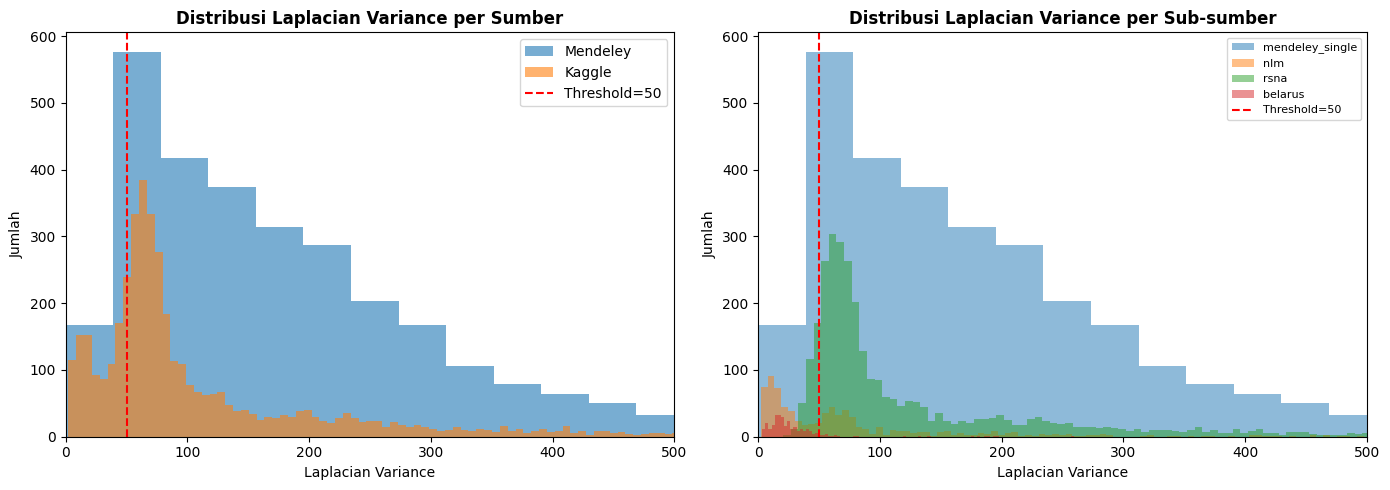

In [57]:
# ============================================================
# 3.4 Deteksi Gambar Blur (Laplacian Variance)
# ============================================================

print('Menghitung Laplacian variance untuk deteksi blur...')

laplacian_vars = []
for idx, row in df_valid.iterrows():
    img = cv2.imread(row['filepath'], cv2.IMREAD_GRAYSCALE)
    if img is not None:
        lap_var = cv2.Laplacian(img, cv2.CV_64F).var()
        laplacian_vars.append(lap_var)
    else:
        laplacian_vars.append(None)
    
    if (idx + 1) % 1000 == 0:
        print(f'  Processed {idx + 1}/{len(df_valid)}...')

df_valid['laplacian_var'] = laplacian_vars
df_raw = df_raw.merge(
    df_valid[['filepath', 'laplacian_var']], on='filepath', how='left'
)

# Visualisasi distribusi Laplacian variance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for source in ['mendeley', 'kaggle']:
    subset = df_raw[df_raw['source'] == source].dropna(subset=['laplacian_var'])
    ax.hist(subset['laplacian_var'], bins=100, alpha=0.6, label=source.capitalize())
ax.axvline(x=LAPLACIAN_THRESHOLD, color='red', linestyle='--', label=f'Threshold={LAPLACIAN_THRESHOLD}')
ax.set_title('Distribusi Laplacian Variance per Sumber', fontweight='bold')
ax.set_xlabel('Laplacian Variance')
ax.set_ylabel('Jumlah')
ax.set_xlim(0, 500)
ax.legend()

ax = axes[1]
for sub_src in df_raw['sub_source'].unique():
    subset = df_raw[df_raw['sub_source'] == sub_src].dropna(subset=['laplacian_var'])
    if len(subset) > 0:
        ax.hist(subset['laplacian_var'], bins=100, alpha=0.5, label=sub_src)
ax.axvline(x=LAPLACIAN_THRESHOLD, color='red', linestyle='--', label=f'Threshold={LAPLACIAN_THRESHOLD}')
ax.set_title('Distribusi Laplacian Variance per Sub-sumber', fontweight='bold')
ax.set_xlabel('Laplacian Variance')
ax.set_ylabel('Jumlah')
ax.set_xlim(0, 500)
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'blur_detection.png'), dpi=150, bbox_inches='tight')
plt.show()

In [58]:
# ============================================================
# 3.5 Checkpoint: Ringkasan Gambar Valid vs Dikecualikan
# ============================================================

# Tandai gambar blur
df_raw['is_blur'] = df_raw['laplacian_var'].apply(
    lambda x: True if (x is not None and x < LAPLACIAN_THRESHOLD) else False
)
df_raw['is_corrupt'] = df_raw['width'].isna()
df_raw['is_excluded'] = df_raw['is_blur'] | df_raw['is_corrupt']

print('=' * 60)
print('CHECKPOINT: Sanity Check — Gambar Dikecualikan')
print('=' * 60)

# Per source
print('\nGambar blur (Laplacian < {}) per source × label:'.format(LAPLACIAN_THRESHOLD))
blur_counts = df_raw[df_raw['is_blur']].groupby(['source', 'label']).size()
print(blur_counts.to_string() if len(blur_counts) > 0 else '  Tidak ada gambar blur.')

# Per sub_source
print('\nGambar blur per sub_source × label:')
blur_sub = df_raw[df_raw['is_blur']].groupby(['sub_source', 'label']).size()
print(blur_sub.to_string() if len(blur_sub) > 0 else '  Tidak ada gambar blur.')

print(f'\nGambar corrupt: {df_raw["is_corrupt"].sum()}')
print(f'Total dikecualikan: {df_raw["is_excluded"].sum()}')
print(f'Total valid: {(~df_raw["is_excluded"]).sum()}')

# Peringatan jika pembuangan timpang
if len(blur_counts) > 0:
    print('\n⚠ PERHATIAN: Periksa apakah pembuangan gambar blur timpang ke satu sumber.')
    print('  Jika signifikan, pertimbangkan threshold lebih longgar untuk sub-sumber tertentu.')

print('=' * 60)

CHECKPOINT: Sanity Check — Gambar Dikecualikan

Gambar blur (Laplacian < 50) per source × label:
source    label 
kaggle    Normal    324
          TB        636
mendeley  TB        320

Gambar blur per sub_source × label:
sub_source       label 
belarus          TB        278
mendeley_single  TB        320
nlm              Normal     29
                 TB        358
rsna             Normal    295

Gambar corrupt: 0
Total dikecualikan: 1280
Total valid: 5928

⚠ PERHATIAN: Periksa apakah pembuangan gambar blur timpang ke satu sumber.
  Jika signifikan, pertimbangkan threshold lebih longgar untuk sub-sumber tertentu.


---
## 4. Preprocessing & Penyeragaman Data

In [59]:
# ============================================================
# 4.1 Filter Gambar Valid & Buat DataFrame Clean
# ============================================================

df_clean = df_raw[~df_raw['is_excluded']].copy().reset_index(drop=True)

# Encode label: Normal=0, TB=1
df_clean['label_encoded'] = (df_clean['label'] == 'TB').astype(int)

# Stratification key untuk splitting
df_clean['strat_key'] = df_clean['label'] + '_' + df_clean['source']

print(f'Dataset clean: {len(df_clean)} gambar')
print()
print('Distribusi per source × label (clean):')
clean_dist = df_clean.groupby(['source', 'label']).size().unstack(fill_value=0)
clean_dist['Total'] = clean_dist.sum(axis=1)
clean_dist.loc['Total'] = clean_dist.sum()
print(clean_dist.to_string())

# Simpan metadata clean
df_clean.to_csv(str(OUTPUT_DIR / 'metadata_clean.csv'), index=False)
print(f'\nMetadata clean disimpan ke: {OUTPUT_DIR / "metadata_clean.csv"}')

Dataset clean: 5928 gambar

Distribusi per source × label (clean):
label     Normal    TB  Total
source                       
kaggle      3176    64   3240
mendeley     514  2174   2688
Total       3690  2238   5928

Metadata clean disimpan ke: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\outputs\metadata_clean.csv


In [60]:
# ============================================================
# 4.2 Checkpoint: Distribusi Setelah Cleaning
# ============================================================

print('=' * 60)
print('CHECKPOINT: Preprocessing — Dataset Clean')
print('=' * 60)
print(f'Total gambar clean: {len(df_clean)}')
print(f'Normal: {(df_clean["label"] == "Normal").sum()}')
print(f'TB:     {(df_clean["label"] == "TB").sum()}')
n_normal_c = (df_clean['label'] == 'Normal').sum()
n_tb_c = (df_clean['label'] == 'TB').sum()
print(f'Rasio TB:Normal = 1:{n_normal_c/n_tb_c:.2f}')
print()
print('Distribusi strat_key:')
print(df_clean['strat_key'].value_counts().to_string())
print('=' * 60)

CHECKPOINT: Preprocessing — Dataset Clean
Total gambar clean: 5928
Normal: 3690
TB:     2238
Rasio TB:Normal = 1:1.65

Distribusi strat_key:
strat_key
Normal_kaggle      3176
TB_mendeley        2174
Normal_mendeley     514
TB_kaggle            64


---
## 5. Data Splitting (Train/Val/Test)

In [61]:
# ============================================================
# 5.1 Stratified Split: 70% Train / 15% Val / 15% Test
# ============================================================

# Tahap 1: train+val (85%) vs test (15%)
df_trainval, df_test = train_test_split(
    df_clean, test_size=0.15, random_state=RANDOM_SEED,
    stratify=df_clean['strat_key']
)

# Tahap 2: train (70/85 ≈ 82.35%) vs val (15/85 ≈ 17.65%) dari trainval
val_ratio = 0.15 / 0.85  # ≈ 0.1765
df_train, df_val = train_test_split(
    df_trainval, test_size=val_ratio, random_state=RANDOM_SEED,
    stratify=df_trainval['strat_key']
)

# Reset index
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

print(f'Train: {len(df_train)} ({len(df_train)/len(df_clean)*100:.1f}%)')
print(f'Val:   {len(df_val)} ({len(df_val)/len(df_clean)*100:.1f}%)')
print(f'Test:  {len(df_test)} ({len(df_test)/len(df_clean)*100:.1f}%)')
print(f'Total: {len(df_train) + len(df_val) + len(df_test)}')

Train: 4148 (70.0%)
Val:   890 (15.0%)
Test:  890 (15.0%)
Total: 5928


In [62]:
# ============================================================
# 5.2 Verifikasi: Tidak Ada Data Leakage
# ============================================================

train_files = set(df_train['filepath'])
val_files = set(df_val['filepath'])
test_files = set(df_test['filepath'])

assert len(train_files & val_files) == 0, 'DATA LEAKAGE: train ∩ val!'
assert len(train_files & test_files) == 0, 'DATA LEAKAGE: train ∩ test!'
assert len(val_files & test_files) == 0, 'DATA LEAKAGE: val ∩ test!'
print('✓ Tidak ada data leakage antar split.')

✓ Tidak ada data leakage antar split.


In [63]:
# ============================================================
# 5.3 Simpan Split ke CSV & Tabel Kontingensi
# ============================================================

df_train.to_csv(str(OUTPUT_DIR / 'train.csv'), index=False)
df_val.to_csv(str(OUTPUT_DIR / 'val.csv'), index=False)
df_test.to_csv(str(OUTPUT_DIR / 'test.csv'), index=False)
print('Split CSV saved to outputs/')

# Tabel kontingensi per split
print('\n' + '=' * 60)
print('CHECKPOINT: Data Splitting')
print('=' * 60)

for name, df_split in [('TRAIN', df_train), ('VAL', df_val), ('TEST', df_test)]:
    print(f'\n--- {name} ({len(df_split)} samples) ---')
    ct = df_split.groupby(['source', 'label']).size().unstack(fill_value=0)
    ct['Total'] = ct.sum(axis=1)
    ct.loc['Total'] = ct.sum()
    print(ct.to_string())

print('=' * 60)

Split CSV saved to outputs/

CHECKPOINT: Data Splitting

--- TRAIN (4148 samples) ---
label     Normal    TB  Total
source                       
kaggle      2222    44   2266
mendeley     360  1522   1882
Total       2582  1566   4148

--- VAL (890 samples) ---
label     Normal   TB  Total
source                      
kaggle       477   10    487
mendeley      77  326    403
Total        554  336    890

--- TEST (890 samples) ---
label     Normal   TB  Total
source                      
kaggle       477   10    487
mendeley      77  326    403
Total        554  336    890


---
## 6. Data Augmentation & tf.data Pipeline

In [64]:
# ============================================================
# 6.1 Fungsi Load & Preprocess Gambar
# ============================================================

def load_and_preprocess_image(filepath, label):
    """Load gambar dari path, central crop untuk buang border/marker, resize ke IMG_SIZE."""
    # Baca file
    img = tf.io.read_file(filepath)
    # Decode (auto-detect format: PNG atau JPEG)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    
    # Terapkan central crop (buang 7.5% dari tiap sisi)
    # Ini menghilangkan marker 'L' / 'R' di pojok dan border hitam
    img = tf.image.central_crop(img, central_fraction=0.85)
    
    # Resize tanpa pad (karena padding menambah border hitam yang jadi spurious feature)
    img = tf.image.resize(img, [IMG_SIZE[0], IMG_SIZE[1]])
    
    # Cast ke float32 [0, 255] 
    img = tf.cast(img, tf.float32)
    return img, label

print('Image loading function defined.')


Image loading function defined.


In [65]:
# ============================================================
# 6.2 Augmentasi Layer (hanya untuk training)
# ============================================================

data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(factor=0.08),        # ~30 degrees
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    layers.RandomZoom(height_factor=0.1, width_factor=0.1),
    layers.RandomBrightness(factor=0.2),
    layers.RandomContrast(factor=0.2),
], name='data_augmentation')

print('Augmentation pipeline defined:')
print('  - RandomFlip (horizontal)')
print('  - RandomRotation (30 degrees)')
print('  - RandomTranslation (5%)')
print('  - RandomZoom (10%)')
print('  - RandomBrightness (20%)')
print('  - RandomContrast (20%)')


Augmentation pipeline defined:
  - RandomFlip (horizontal)
  - RandomRotation (30 degrees)
  - RandomTranslation (5%)
  - RandomZoom (10%)
  - RandomBrightness (20%)
  - RandomContrast (20%)


In [66]:
# ============================================================
# 6.3 Build tf.data.Dataset Pipeline
# ============================================================

def build_dataset(df_split, preprocess_fn, augment=False, shuffle=False):
    """Build tf.data.Dataset dari dataframe split."""
    filepaths = df_split['filepath'].values
    labels = df_split['label_encoded'].values.astype(np.float32)
    
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    
    if shuffle:
        ds = ds.shuffle(buffer_size=len(filepaths), seed=RANDOM_SEED)
    
    # Load & resize
    ds = ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    
    # Batch first (untuk menghindari ValueError pada data augmentation layer)
    ds = ds.batch(BATCH_SIZE)
    
    # Augmentasi (hanya training)
    if augment:
        ds = ds.map(lambda img, lbl: (data_augmentation(img, training=True), lbl),
                    num_parallel_calls=tf.data.AUTOTUNE)
    
    # Apply architecture-specific preprocessing
    ds = ds.map(lambda img, lbl: (preprocess_fn(img), lbl),
                num_parallel_calls=tf.data.AUTOTUNE)
    
    ds = ds.prefetch(tf.data.AUTOTUNE)
    
    return ds

print('Dataset pipeline builder defined.')


Dataset pipeline builder defined.


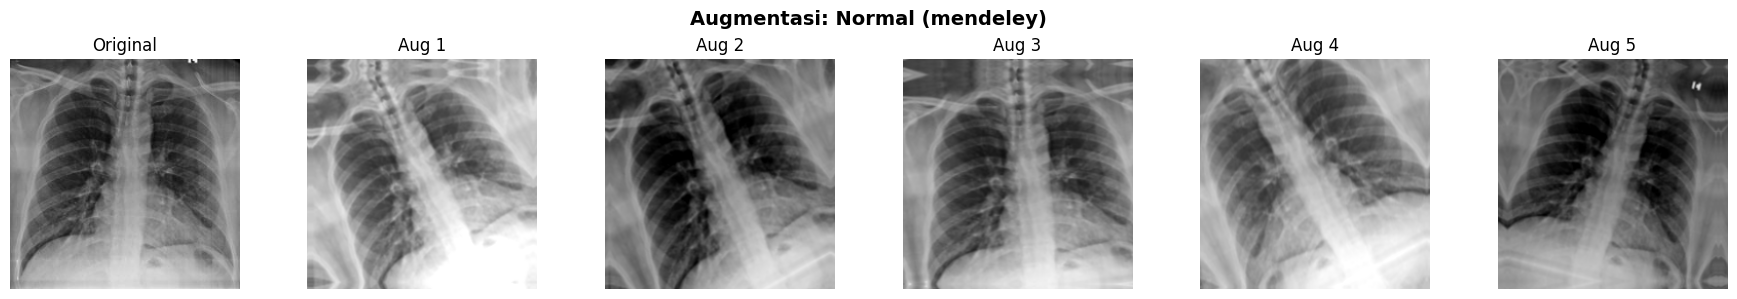

In [67]:
# ============================================================
# 6.4 Visualisasi Augmentasi
# ============================================================

# Ambil 1 gambar dan tampilkan 5 versi augmentasi
sample_row = df_train.iloc[0]
sample_img = cv2.imread(sample_row['filepath'])
sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
sample_img = cv2.resize(sample_img, IMG_SIZE)
sample_tensor = tf.cast(tf.expand_dims(sample_img, 0), tf.float32)

fig, axes = plt.subplots(1, 6, figsize=(18, 3))
fig.suptitle(f'Augmentasi: {sample_row["label"]} ({sample_row["source"]})', fontsize=14, fontweight='bold')

axes[0].imshow(sample_img)
axes[0].set_title('Original')
axes[0].axis('off')

for i in range(1, 6):
    aug_img = data_augmentation(sample_tensor, training=True)
    aug_np = aug_img.numpy()[0].astype(np.uint8)
    axes[i].imshow(aug_np)
    axes[i].set_title(f'Aug {i}')
    axes[i].axis('off')

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'augmentation_samples.png'), dpi=150, bbox_inches='tight')
plt.show()

In [68]:
# ============================================================
# 6.5 Checkpoint: Verifikasi Pipeline
# ============================================================

# Test dengan EfficientNetB0 preprocessing
test_ds = build_dataset(df_train.head(BATCH_SIZE), efn_preprocess, augment=True, shuffle=False)
for batch_imgs, batch_labels in test_ds.take(1):
    print('=' * 60)
    print('CHECKPOINT: tf.data Pipeline')
    print('=' * 60)
    print(f'Batch image shape : {batch_imgs.shape}')
    print(f'Batch label shape : {batch_labels.shape}')
    print(f'Image dtype       : {batch_imgs.dtype}')
    print(f'Pixel range       : [{batch_imgs.numpy().min():.2f}, {batch_imgs.numpy().max():.2f}]')
    print(f'Label values      : {batch_labels.numpy()[:10]}...')
    print('=' * 60)

del test_ds

CHECKPOINT: tf.data Pipeline
Batch image shape : (32, 224, 224, 3)
Batch label shape : (32,)
Image dtype       : <dtype: 'float32'>
Pixel range       : [0.00, 255.00]
Label values      : [0. 0. 1. 0. 0. 1. 0. 0. 0. 1.]...


---
## 7. Model Architecture (CNN + Transfer Learning)

In [69]:
# ============================================================
# 7.1 Fungsi Build Model
# ============================================================

def build_model(architecture_name, freeze_base=True):
    """
    Build CNN model dengan transfer learning.
    
    Args:
        architecture_name: 'EfficientNetB0', 'ResNet50', atau 'VGG16'
        freeze_base: True untuk freeze base model (tahap 1)
    
    Returns:
        model: Compiled Keras model
        preprocess_fn: Architecture-specific preprocessing function
    """
    input_shape = (*IMG_SIZE, 3)
    
    if architecture_name == 'EfficientNetB0':
        base_model = EfficientNetB0(
            weights='imagenet', include_top=False, input_shape=input_shape
        )
        preprocess_fn = efn_preprocess
    elif architecture_name == 'ResNet50':
        base_model = ResNet50(
            weights='imagenet', include_top=False, input_shape=input_shape
        )
        preprocess_fn = resnet_preprocess
    elif architecture_name == 'VGG16':
        base_model = VGG16(
            weights='imagenet', include_top=False, input_shape=input_shape
        )
        preprocess_fn = vgg_preprocess
    else:
        raise ValueError(f'Arsitektur tidak dikenal: {architecture_name}')
    
    # Freeze base model
    base_model.trainable = not freeze_base
    
    # Head classifier
    x = base_model.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    
    model = Model(inputs=base_model.input, outputs=outputs, name=architecture_name)
    
    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE_STAGE1),
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            AUC(name='auc'),
            Precision(name='precision'),
            Recall(name='recall'),
        ]
    )
    
    return model, preprocess_fn, base_model

print('build_model() function defined.')

build_model() function defined.


In [70]:
# ============================================================
# 7.2 Fungsi Unfreeze untuk Fine-tuning Tahap 2
# ============================================================

def unfreeze_top_layers(model, base_model, architecture_name):
    """
    Unfreeze top layers dari base model untuk fine-tuning.
    Jumlah layers yang di-unfreeze tergantung arsitektur.
    """
    base_model.trainable = True
    
    if architecture_name == 'EfficientNetB0':
        # Freeze semua kecuali 20 layer terakhir
        fine_tune_at = len(base_model.layers) - 20
    elif architecture_name == 'ResNet50':
        # Freeze semua kecuali 30 layer terakhir (stage 5)
        fine_tune_at = len(base_model.layers) - 30
    elif architecture_name == 'VGG16':
        # Freeze semua kecuali 4 layer terakhir (block5)
        fine_tune_at = len(base_model.layers) - 4
    else:
        fine_tune_at = len(base_model.layers) - 20
    
    for layer in base_model.layers[:fine_tune_at]:
        layer.trainable = False
    
    # Recompile dengan learning rate lebih kecil
    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE_STAGE2),
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            AUC(name='auc'),
            Precision(name='precision'),
            Recall(name='recall'),
        ]
    )
    
    trainable = sum(1 for l in base_model.layers if l.trainable)
    frozen = sum(1 for l in base_model.layers if not l.trainable)
    print(f'  Fine-tuning {architecture_name}: {trainable} trainable, {frozen} frozen layers')
    
    return model

print('unfreeze_top_layers() function defined.')

unfreeze_top_layers() function defined.


In [71]:
# ============================================================
# 7.3 Checkpoint: Model Summary Comparison
# ============================================================

print('=' * 60)
print('CHECKPOINT: Model Architecture Comparison')
print('=' * 60)

for arch_name in ARCHITECTURES:
    model_tmp, _, _ = build_model(arch_name, freeze_base=True)
    total_params = model_tmp.count_params()
    trainable_params = sum(tf.keras.backend.count_params(w) for w in model_tmp.trainable_weights)
    non_trainable_params = total_params - trainable_params
    print(f'\n{arch_name}:')
    print(f'  Total params     : {total_params:,}')
    print(f'  Trainable params : {trainable_params:,}')
    print(f'  Non-trainable    : {non_trainable_params:,}')
    del model_tmp
    tf.keras.backend.clear_session()

print('\n' + '=' * 60)

CHECKPOINT: Model Architecture Comparison

EfficientNetB0:
  Total params     : 4,411,556
  Trainable params : 361,473
  Non-trainable    : 4,050,083

ResNet50:
  Total params     : 24,146,305
  Trainable params : 558,081
  Non-trainable    : 23,588,224

VGG16:
  Total params     : 14,880,065
  Trainable params : 164,865
  Non-trainable    : 14,715,200



---
## 8. Training

In [72]:
# ============================================================
# 8.1 Compute Class Weights (opsional)
# ============================================================

train_labels = df_train['label_encoded'].values
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=train_labels
)
class_weight_dict = {0: class_weights_array[0], 1: class_weights_array[1]}
print(f'Class weights: {class_weight_dict}')
print(f'  Normal (0): {class_weight_dict[0]:.4f}')
print(f'  TB (1):     {class_weight_dict[1]:.4f}')

Class weights: {0: np.float64(0.8032532920216886), 1: np.float64(1.3243933588761174)}
  Normal (0): 0.8033
  TB (1):     1.3244


In [73]:
# ============================================================
# 8.2 Training Loop: 3 Arsitektur × 2 Tahap (Resumable)
# ============================================================
import json
from pathlib import Path

all_histories = {}  # {arch_name: {'stage1': history, 'stage2': history}}
all_models = {}     # {arch_name: trained_model}
preprocess_fns = {} # {arch_name: preprocess_fn}

for arch_name in ARCHITECTURES:
    print('\n' + '=' * 60)
    print(f'TRAINING / LOADING: {arch_name}')
    print('=' * 60)
    
    # Clear session untuk memastikan memori bersih
    tf.keras.backend.clear_session()
    
    # Build model (selalu jalankan untuk inisialisasi struktur & preprocess_fn)
    model, preprocess_fn, base_model = build_model(arch_name, freeze_base=True)
    preprocess_fns[arch_name] = preprocess_fn
    
    # Path file checkpoint & history
    stage1_path = OUTPUT_DIR / f'best_{arch_name}_stage1.keras'
    final_path = OUTPUT_DIR / f'best_{arch_name}_final.keras'
    history_path = OUTPUT_DIR / f'history_{arch_name}.json'
    
    # 1. Cek apakah model ini sudah selesai ditraining sepenuhnya (Tahap 1 & 2)
    if final_path.exists():
        print(f'✓ Model final untuk {arch_name} ditemukan di disk.')
        print(f'  Memuat model final...')
        # Untuk memuat bobot final (yang menyertakan unfreeze top layers),
        # model harus di-unfreeze terlebih dahulu agar arsitekturnya cocok
        model = unfreeze_top_layers(model, base_model, arch_name)
        model.load_weights(str(final_path))
        
        # Coba muat history dari disk jika ada
        if history_path.exists():
            try:
                with open(history_path, 'r') as f:
                    all_histories[arch_name] = json.load(f)
                print(f'  ✓ History training berhasil dimuat.')
            except Exception as e:
                print(f'  ⚠ Gagal memuat history dari disk: {e}')
                all_histories[arch_name] = {'stage1': {}, 'stage2': {}}
        else:
            all_histories[arch_name] = {'stage1': {}, 'stage2': {}}
            
        all_models[arch_name] = model
        print(f'✓ {arch_name} berhasil dimuat dari checkpoint. Melewati proses training.')
        continue
    
    # Jika model final belum ada, kita butuh dataset untuk training
    train_ds = build_dataset(df_train, preprocess_fn, augment=True, shuffle=True)
    val_ds = build_dataset(df_val, preprocess_fn, augment=False, shuffle=False)
    
    # --- TAHAP 1: Feature Extraction (Frozen Base) ---
    history_s1_dict = None
    
    # Cek apakah checkpoint Stage 1 sudah ada
    if stage1_path.exists():
        print(f'✓ Checkpoint Stage 1 untuk {arch_name} ditemukan di disk.')
        print(f'  Memuat bobot Stage 1...')
        model.load_weights(str(stage1_path))
        
        # Coba muat history Stage 1 dari disk jika ada
        if history_path.exists():
            try:
                with open(history_path, 'r') as f:
                    saved_hist = json.load(f)
                    if 'stage1' in saved_hist:
                        history_s1_dict = saved_hist['stage1']
                        print(f'  ✓ History Stage 1 berhasil dimuat.')
            except Exception as e:
                pass
        
        if history_s1_dict is None:
            history_s1_dict = {}
            print(f'  ⚠ History Stage 1 tidak ditemukan di disk, dilanjutkan dengan log kosong.')
    else:
        print(f'\n--- Tahap 1: Feature Extraction (Frozen Base) ---')
        callbacks_s1 = [
            EarlyStopping(
                monitor='val_auc', patience=5,
                restore_best_weights=True, mode='max', verbose=1
            ),
            ReduceLROnPlateau(
                monitor='val_loss', factor=0.5, patience=3, verbose=1
            ),
            ModelCheckpoint(
                filepath=str(stage1_path),
                monitor='val_auc', save_best_only=True, mode='max', verbose=0
            ),
        ]
        
        history_s1 = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=EPOCHS_STAGE1,
            callbacks=callbacks_s1,
            class_weight=class_weight_dict,
            verbose=1
        )
        history_s1_dict = history_s1.history
        print(f'  Best val_auc (Stage 1): {max(history_s1_dict["val_auc"]):.4f}')
        
        # Simpan history sementara (hanya Stage 1) ke disk agar aman
        try:
            temp_hist = {
                'stage1': {k: [float(v) for v in vals] for k, vals in history_s1_dict.items()},
                'stage2': {}
            }
            with open(history_path, 'w') as f:
                json.dump(temp_hist, f, indent=2)
        except Exception as e:
            print(f'  ⚠ Gagal menyimpan history sementara: {e}')
            
    # --- TAHAP 2: Fine-Tuning (Unfreeze Top Layers) ---
    print(f'\n--- Tahap 2: Fine-Tuning ---')
    model = unfreeze_top_layers(model, base_model, arch_name)
    
    callbacks_s2 = [
        EarlyStopping(
            monitor='val_auc', patience=5,
            restore_best_weights=True, mode='max', verbose=1
        ),
        ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=3, verbose=1
        ),
        ModelCheckpoint(
            filepath=str(final_path),
            monitor='val_auc', save_best_only=True, mode='max', verbose=0
        ),
    ]
    
    history_s2 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS_STAGE2,
        callbacks=callbacks_s2,
        class_weight=class_weight_dict,
        verbose=1
    )
    history_s2_dict = history_s2.history
    print(f'  Best val_auc (Stage 2): {max(history_s2_dict["val_auc"]):.4f}')
    
    # Gabungkan history lengkap ke dalam all_histories
    all_histories[arch_name] = {
        'stage1': history_s1_dict,
        'stage2': history_s2_dict,
    }
    all_models[arch_name] = model
    
    # Simpan history lengkap ke disk
    try:
        hist_serializable = {
            'stage1': {k: [float(v) for v in vals] for k, vals in history_s1_dict.items()} if history_s1_dict else {},
            'stage2': {k: [float(v) for v in vals] for k, vals in history_s2_dict.items()}
        }
        with open(history_path, 'w') as f:
            json.dump(hist_serializable, f, indent=2)
        print(f'  ✓ History lengkap disimpan ke disk.')
    except Exception as e:
        print(f'  ⚠ Gagal menyimpan history lengkap ke disk: {e}')
        
    print(f'\n✓ {arch_name} training complete.')

print('\n' + '=' * 60)
print('ALL TRAINING COMPLETE / LOADED')
print('=' * 60)



TRAINING / LOADING: EfficientNetB0
✓ Model final untuk EfficientNetB0 ditemukan di disk.
  Memuat model final...
  Fine-tuning EfficientNetB0: 20 trainable, 218 frozen layers
  ✓ History training berhasil dimuat.
✓ EfficientNetB0 berhasil dimuat dari checkpoint. Melewati proses training.

TRAINING / LOADING: ResNet50
✓ Model final untuk ResNet50 ditemukan di disk.
  Memuat model final...
  Fine-tuning ResNet50: 30 trainable, 145 frozen layers
  ✓ History training berhasil dimuat.
✓ ResNet50 berhasil dimuat dari checkpoint. Melewati proses training.

TRAINING / LOADING: VGG16
✓ Model final untuk VGG16 ditemukan di disk.
  Memuat model final...
  Fine-tuning VGG16: 4 trainable, 15 frozen layers
  ✓ History training berhasil dimuat.
✓ VGG16 berhasil dimuat dari checkpoint. Melewati proses training.

ALL TRAINING COMPLETE / LOADED


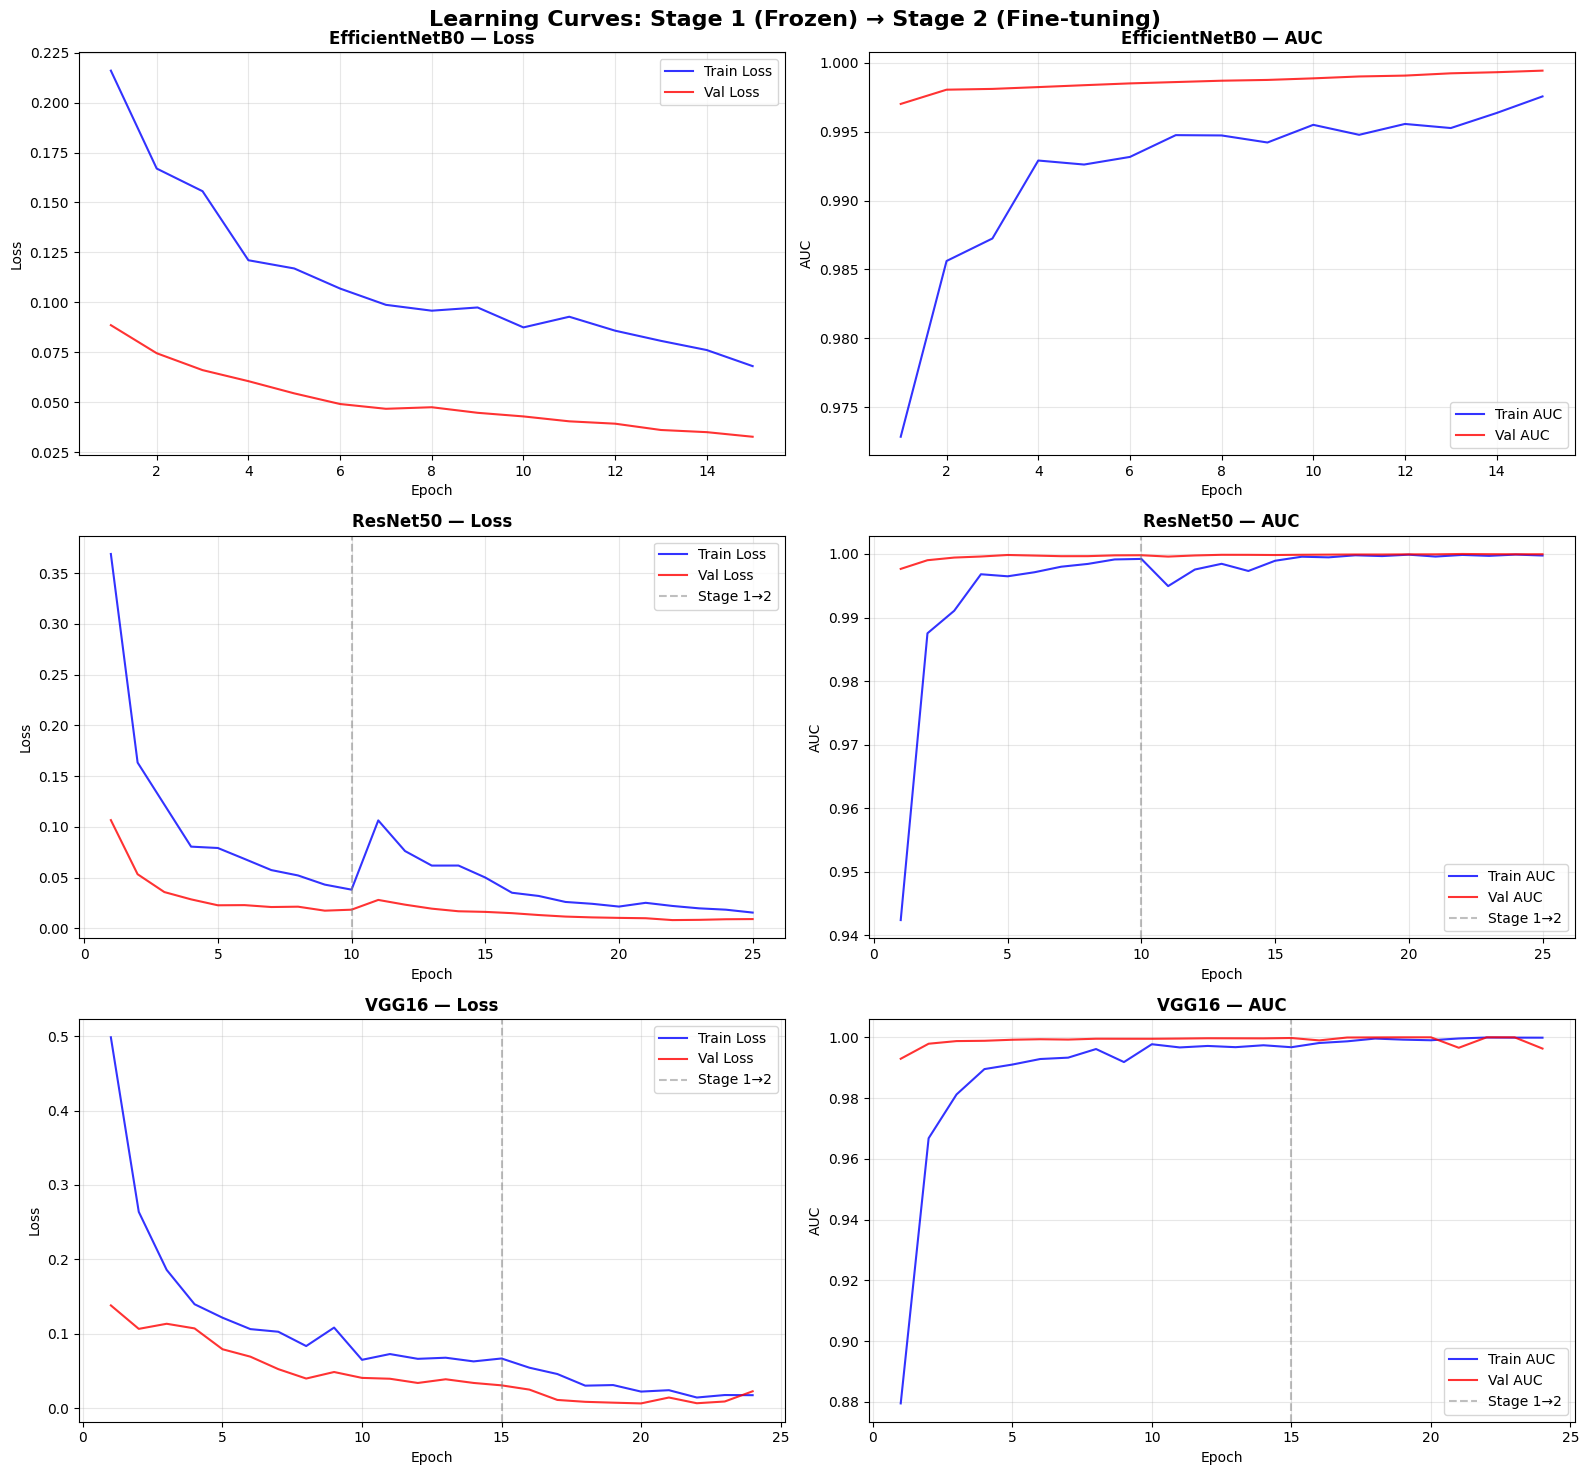


Ringkasan Performa Validasi (Best):
Architecture         Val AUC (S1)    Val AUC (S2)   
--------------------------------------------------
EfficientNetB0       0.0000          0.9994         
ResNet50             0.9998          1.0000         
VGG16                0.9998          1.0000         


In [74]:
# ============================================================
# 8.3 Plot Learning Curves
# ============================================================

fig, axes = plt.subplots(len(ARCHITECTURES), 2, figsize=(16, 5 * len(ARCHITECTURES)))
fig.suptitle('Learning Curves: Stage 1 (Frozen) → Stage 2 (Fine-tuning)', fontsize=16, fontweight='bold')

for i, arch_name in enumerate(ARCHITECTURES):
    hist = all_histories[arch_name]
    
    # Gabungkan stage 1 dan stage 2 dengan fallback jika kosong
    s1_loss = hist.get('stage1', {}).get('loss', []) if hist.get('stage1') else []
    s2_loss = hist.get('stage2', {}).get('loss', []) if hist.get('stage2') else []
    s1_val_loss = hist.get('stage1', {}).get('val_loss', []) if hist.get('stage1') else []
    s2_val_loss = hist.get('stage2', {}).get('val_loss', []) if hist.get('stage2') else []
    
    s1_auc = hist.get('stage1', {}).get('auc', []) if hist.get('stage1') else []
    s2_auc = hist.get('stage2', {}).get('auc', []) if hist.get('stage2') else []
    s1_val_auc = hist.get('stage1', {}).get('val_auc', []) if hist.get('stage1') else []
    s2_val_auc = hist.get('stage2', {}).get('val_auc', []) if hist.get('stage2') else []
    
    loss_train = s1_loss + s2_loss
    loss_val = s1_val_loss + s2_val_loss
    auc_train = s1_auc + s2_auc
    auc_val = s1_val_auc + s2_val_auc
    
    stage1_epochs = len(s1_loss)
    epochs_range = range(1, len(loss_train) + 1)
    
    # Loss
    ax = axes[i, 0]
    ax.plot(epochs_range, loss_train, 'b-', label='Train Loss', alpha=0.8)
    ax.plot(epochs_range, loss_val, 'r-', label='Val Loss', alpha=0.8)
    if stage1_epochs > 0:
        ax.axvline(x=stage1_epochs, color='gray', linestyle='--', alpha=0.5, label='Stage 1→2')
    ax.set_title(f'{arch_name} — Loss', fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # AUC
    ax = axes[i, 1]
    ax.plot(epochs_range, auc_train, 'b-', label='Train AUC', alpha=0.8)
    ax.plot(epochs_range, auc_val, 'r-', label='Val AUC', alpha=0.8)
    if stage1_epochs > 0:
        ax.axvline(x=stage1_epochs, color='gray', linestyle='--', alpha=0.5, label='Stage 1→2')
    ax.set_title(f'{arch_name} — AUC', fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('AUC')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'learning_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

# Tabel ringkasan
print('\nRingkasan Performa Validasi (Best):')
print(f'{"Architecture":<20} {"Val AUC (S1)":<15} {"Val AUC (S2)":<15}')
print('-' * 50)
for arch_name in ARCHITECTURES:
    s1_auc_vals = all_histories[arch_name].get('stage1', {}).get('val_auc', []) if all_histories[arch_name].get('stage1') else []
    s2_auc_vals = all_histories[arch_name].get('stage2', {}).get('val_auc', []) if all_histories[arch_name].get('stage2') else []
    s1_auc = max(s1_auc_vals) if s1_auc_vals else 0.0
    s2_auc = max(s2_auc_vals) if s2_auc_vals else 0.0
    print(f'{arch_name:<20} {s1_auc:<15.4f} {s2_auc:<15.4f}')


---
## 9. Evaluation

In [75]:
# ============================================================
# 9.1 Evaluasi pada Test Set — Ketiga Arsitektur
# ============================================================

eval_results = {}  # {arch_name: {metrics...}}
all_predictions = {}  # {arch_name: {'y_true': ..., 'y_prob': ...}}

for arch_name in ARCHITECTURES:
    print(f'\nEvaluating {arch_name} on test set...')
    
    model = all_models[arch_name]
    preprocess_fn = preprocess_fns[arch_name]
    
    # Build test dataset
    test_ds = build_dataset(df_test, preprocess_fn, augment=False, shuffle=False)
    
    # Predict probabilities
    y_prob = model.predict(test_ds, verbose=0).flatten()
    y_true = df_test['label_encoded'].values
    y_pred = (y_prob >= 0.5).astype(int)
    
    # Metrics
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc_val = auc(fpr, tpr)
    
    cr = classification_report(y_true, y_pred, target_names=['Normal', 'TB'], output_dict=True)
    
    eval_results[arch_name] = {
        'accuracy': acc,
        'f1': f1,
        'auc_roc': roc_auc_val,
        'precision_tb': cr['TB']['precision'],
        'recall_tb': cr['TB']['recall'],
        'precision_normal': cr['Normal']['precision'],
        'recall_normal': cr['Normal']['recall'],
    }
    
    all_predictions[arch_name] = {
        'y_true': y_true,
        'y_prob': y_prob,
        'y_pred': y_pred,
        'fpr': fpr,
        'tpr': tpr,
    }
    
    print(f'  Accuracy: {acc:.4f} | AUC: {roc_auc_val:.4f} | F1: {f1:.4f}')
    print(f'  TB Recall: {cr["TB"]["recall"]:.4f} | TB Precision: {cr["TB"]["precision"]:.4f}')


Evaluating EfficientNetB0 on test set...
  Accuracy: 0.9764 | AUC: 0.9926 | F1: 0.9689
  TB Recall: 0.9732 | TB Precision: 0.9646

Evaluating ResNet50 on test set...
  Accuracy: 0.9809 | AUC: 0.9973 | F1: 0.9750
  TB Recall: 0.9851 | TB Precision: 0.9650

Evaluating VGG16 on test set...
  Accuracy: 0.9337 | AUC: 0.9979 | F1: 0.9188
  TB Recall: 0.9940 | TB Precision: 0.8542


In [76]:
# ============================================================
# 9.2 Tabel Perbandingan Arsitektur
# ============================================================

print('\n' + '=' * 80)
print('PERBANDINGAN ARSITEKTUR — TEST SET')
print('=' * 80)

eval_df = pd.DataFrame(eval_results).T
eval_df.index.name = 'Architecture'
print(eval_df.round(4).to_string())

# Pilih arsitektur terbaik (berdasarkan AUC + Recall TB)
eval_df['combined_score'] = eval_df['auc_roc'] * 0.5 + eval_df['recall_tb'] * 0.5
best_arch = eval_df['combined_score'].idxmax()
print(f'\n★ Arsitektur terbaik: {best_arch}')
print(f'  (Berdasarkan combined score = 0.5×AUC + 0.5×Recall_TB)')

# Simpan tabel
eval_df.to_csv(str(OUTPUT_DIR / 'architecture_comparison.csv'))
print('=' * 80)


PERBANDINGAN ARSITEKTUR — TEST SET
                accuracy      f1  auc_roc  precision_tb  recall_tb  precision_normal  recall_normal
Architecture                                                                                       
EfficientNetB0    0.9764  0.9689   0.9926        0.9646     0.9732            0.9837         0.9783
ResNet50          0.9809  0.9750   0.9973        0.9650     0.9851            0.9909         0.9783
VGG16             0.9337  0.9188   0.9979        0.8542     0.9940            0.9960         0.8971

★ Arsitektur terbaik: VGG16
  (Berdasarkan combined score = 0.5×AUC + 0.5×Recall_TB)


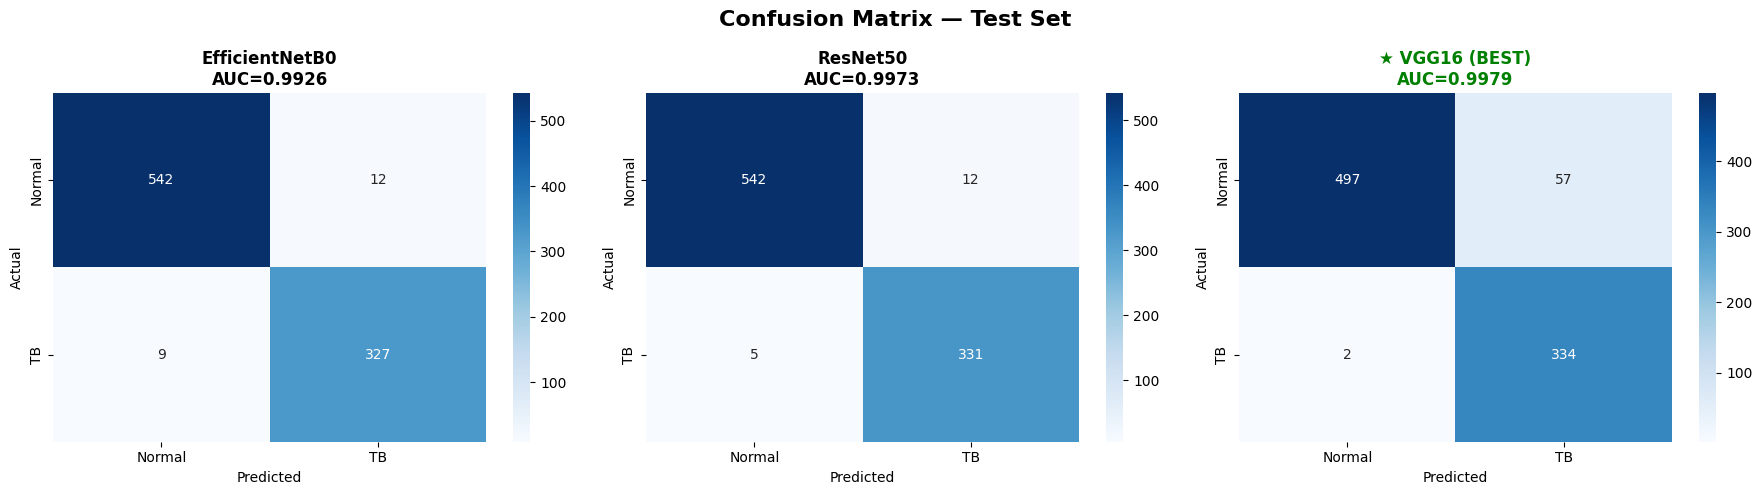

In [77]:
# ============================================================
# 9.3 Confusion Matrix — Ketiga Arsitektur
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Confusion Matrix — Test Set', fontsize=16, fontweight='bold')

for i, arch_name in enumerate(ARCHITECTURES):
    ax = axes[i]
    preds = all_predictions[arch_name]
    cm = confusion_matrix(preds['y_true'], preds['y_pred'])
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Normal', 'TB'], yticklabels=['Normal', 'TB'])
    ax.set_title(f'{arch_name}\nAUC={eval_results[arch_name]["auc_roc"]:.4f}',
                fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    
    # Highlight best
    if arch_name == best_arch:
        ax.set_title(f'★ {arch_name} (BEST)\nAUC={eval_results[arch_name]["auc_roc"]:.4f}',
                    fontweight='bold', color='green')

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'confusion_matrices.png'), dpi=150, bbox_inches='tight')
plt.show()

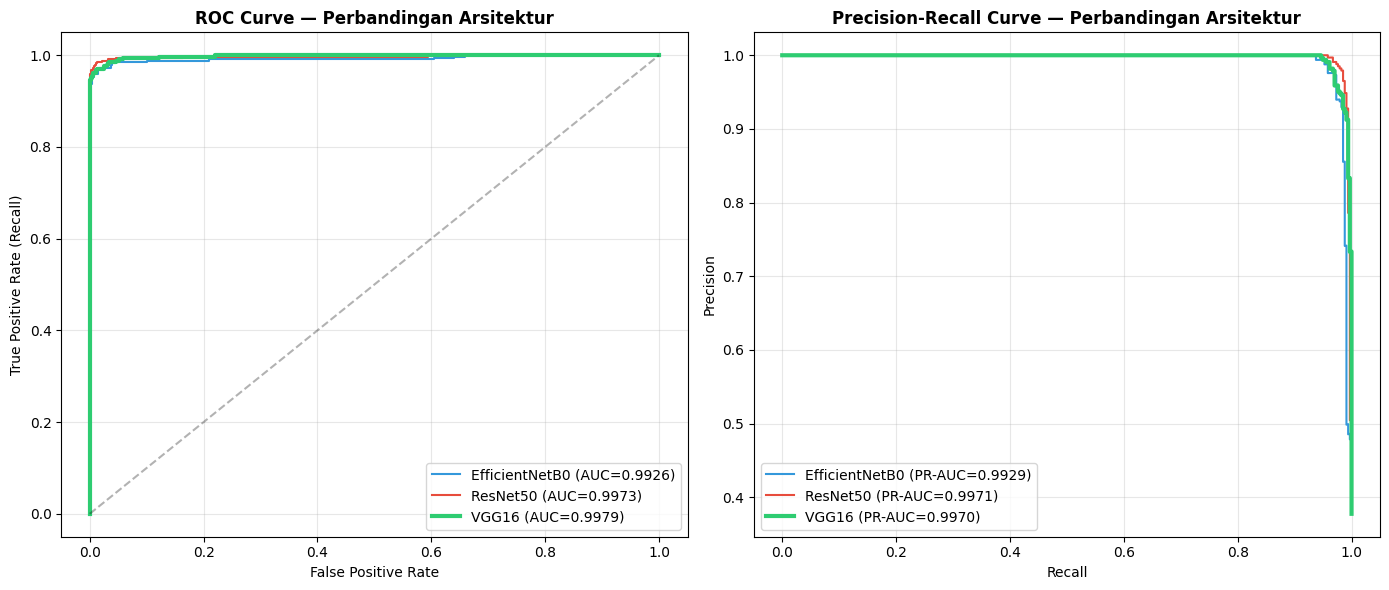

In [78]:
# ============================================================
# 9.4 ROC Curve & Precision-Recall Curve
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

colors = ['#3498db', '#e74c3c', '#2ecc71']

# ROC Curve
ax = axes[0]
for i, arch_name in enumerate(ARCHITECTURES):
    preds = all_predictions[arch_name]
    label = f'{arch_name} (AUC={eval_results[arch_name]["auc_roc"]:.4f})'
    lw = 3 if arch_name == best_arch else 1.5
    ax.plot(preds['fpr'], preds['tpr'], color=colors[i], lw=lw, label=label)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax.set_title('ROC Curve — Perbandingan Arsitektur', fontweight='bold')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate (Recall)')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)

# Precision-Recall Curve
ax = axes[1]
for i, arch_name in enumerate(ARCHITECTURES):
    preds = all_predictions[arch_name]
    prec, rec, _ = precision_recall_curve(preds['y_true'], preds['y_prob'])
    pr_auc = auc(rec, prec)
    label = f'{arch_name} (PR-AUC={pr_auc:.4f})'
    lw = 3 if arch_name == best_arch else 1.5
    ax.plot(rec, prec, color=colors[i], lw=lw, label=label)

ax.set_title('Precision-Recall Curve — Perbandingan Arsitektur', fontweight='bold')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.legend(loc='lower left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'roc_pr_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

Threshold Optimization untuk model terbaik: VGG16
Target: Recall TB ≥ 0.95 (minimisasi false negative untuk skrining)

Threshold default (0.50):
  Accuracy=0.9337 | Recall_TB=0.9940 | Precision_TB=0.8542 | F1_TB=0.9188

Threshold optimal (0.98):
  Accuracy=0.9753 | Recall_TB=0.9762 | Precision_TB=0.9591 | F1_TB=0.9676


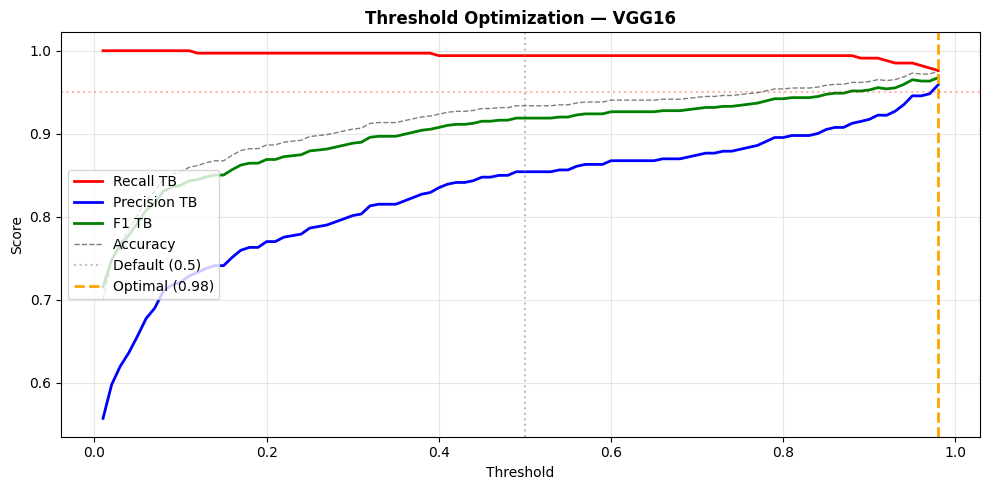

In [79]:
# ============================================================
# 9.5 Threshold Optimization (Recall TB ≥ 0.95)
# ============================================================

print('Threshold Optimization untuk model terbaik:', best_arch)
print('Target: Recall TB ≥ 0.95 (minimisasi false negative untuk skrining)')
print()

preds = all_predictions[best_arch]
y_true = preds['y_true']
y_prob = preds['y_prob']

# Cari threshold yang memaksimalkan recall TB ≥ 0.95
thresholds = np.arange(0.01, 0.99, 0.01)
results = []

for thresh in thresholds:
    y_pred_t = (y_prob >= thresh).astype(int)
    cr_t = classification_report(y_true, y_pred_t, target_names=['Normal', 'TB'],
                                  output_dict=True, zero_division=0)
    results.append({
        'threshold': thresh,
        'accuracy': accuracy_score(y_true, y_pred_t),
        'recall_tb': cr_t['TB']['recall'],
        'precision_tb': cr_t['TB']['precision'],
        'f1_tb': cr_t['TB']['f1-score'],
        'recall_normal': cr_t['Normal']['recall'],
    })

results_df = pd.DataFrame(results)

# Filter threshold yang memberikan recall TB ≥ 0.95
high_recall = results_df[results_df['recall_tb'] >= 0.95]
if len(high_recall) > 0:
    # Pilih threshold dengan F1 tertinggi di antara yang recall ≥ 0.95
    optimal_row = high_recall.loc[high_recall['f1_tb'].idxmax()]
    optimal_threshold = optimal_row['threshold']
else:
    # Jika tidak ada yang ≥ 0.95, pilih threshold dengan recall tertinggi
    optimal_row = results_df.loc[results_df['recall_tb'].idxmax()]
    optimal_threshold = optimal_row['threshold']

print(f'Threshold default (0.50):')
default_row = results_df[results_df['threshold'] == 0.5].iloc[0]
print(f'  Accuracy={default_row["accuracy"]:.4f} | Recall_TB={default_row["recall_tb"]:.4f} | Precision_TB={default_row["precision_tb"]:.4f} | F1_TB={default_row["f1_tb"]:.4f}')

print(f'\nThreshold optimal ({optimal_threshold:.2f}):')
print(f'  Accuracy={optimal_row["accuracy"]:.4f} | Recall_TB={optimal_row["recall_tb"]:.4f} | Precision_TB={optimal_row["precision_tb"]:.4f} | F1_TB={optimal_row["f1_tb"]:.4f}')

# Plot threshold vs metrics
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(results_df['threshold'], results_df['recall_tb'], 'r-', label='Recall TB', lw=2)
ax.plot(results_df['threshold'], results_df['precision_tb'], 'b-', label='Precision TB', lw=2)
ax.plot(results_df['threshold'], results_df['f1_tb'], 'g-', label='F1 TB', lw=2)
ax.plot(results_df['threshold'], results_df['accuracy'], 'k--', label='Accuracy', lw=1, alpha=0.5)
ax.axvline(x=0.5, color='gray', linestyle=':', alpha=0.5, label='Default (0.5)')
ax.axvline(x=optimal_threshold, color='orange', linestyle='--', lw=2, label=f'Optimal ({optimal_threshold:.2f})')
ax.axhline(y=0.95, color='red', linestyle=':', alpha=0.3)
ax.set_title(f'Threshold Optimization — {best_arch}', fontweight='bold')
ax.set_xlabel('Threshold')
ax.set_ylabel('Score')
ax.legend(loc='center left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'threshold_optimization.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## 10. Error Analysis & Domain Shift Check

In [80]:
# ============================================================
# 10.1 Breakdown Metrik per Sumber Dataset
# ============================================================

print('=' * 60)
print(f'DOMAIN SHIFT ANALYSIS — {best_arch}')
print('=' * 60)

best_model = all_models[best_arch]
best_preprocess = preprocess_fns[best_arch]

# Prediksi pada test set
preds = all_predictions[best_arch]
y_true_all = preds['y_true']
y_prob_all = preds['y_prob']
y_pred_all = preds['y_pred']

# Tambahkan prediksi ke df_test
df_test_eval = df_test.copy()
df_test_eval['y_prob'] = y_prob_all
df_test_eval['y_pred'] = y_pred_all
df_test_eval['correct'] = (df_test_eval['label_encoded'] == df_test_eval['y_pred'])

# Breakdown per source
print('\n--- Metrik per Sumber ---')
for source in ['mendeley', 'kaggle']:
    mask = df_test_eval['source'] == source
    y_t = df_test_eval.loc[mask, 'label_encoded'].values
    y_p = df_test_eval.loc[mask, 'y_pred'].values
    y_pr = df_test_eval.loc[mask, 'y_prob'].values
    
    if len(np.unique(y_t)) < 2:
        print(f'\n{source.upper()}: hanya satu kelas di test set, skip AUC.')
        continue
    
    acc = accuracy_score(y_t, y_p)
    f1 = f1_score(y_t, y_p)
    fpr_s, tpr_s, _ = roc_curve(y_t, y_pr)
    auc_s = auc(fpr_s, tpr_s)
    cr = classification_report(y_t, y_p, target_names=['Normal', 'TB'], output_dict=True)
    
    print(f'\n{source.upper()} (n={mask.sum()}):')
    print(f'  Accuracy : {acc:.4f}')
    print(f'  AUC-ROC  : {auc_s:.4f}')
    print(f'  F1       : {f1:.4f}')
    print(f'  TB Recall    : {cr["TB"]["recall"]:.4f}')
    print(f'  TB Precision : {cr["TB"]["precision"]:.4f}')

# Breakdown per sub_source
print('\n--- Metrik per Sub-sumber ---')
for sub_src in sorted(df_test_eval['sub_source'].unique()):
    mask = df_test_eval['sub_source'] == sub_src
    n = mask.sum()
    if n == 0:
        continue
    y_t = df_test_eval.loc[mask, 'label_encoded'].values
    y_p = df_test_eval.loc[mask, 'y_pred'].values
    acc = accuracy_score(y_t, y_p)
    print(f'  {sub_src:<20} n={n:<5} accuracy={acc:.4f}')

DOMAIN SHIFT ANALYSIS — VGG16

--- Metrik per Sumber ---

MENDELEY (n=403):
  Accuracy : 0.9231
  AUC-ROC  : 0.9972
  F1       : 0.9546
  TB Recall    : 1.0000
  TB Precision : 0.9132

KAGGLE (n=487):
  Accuracy : 0.9425
  AUC-ROC  : 0.9717
  F1       : 0.3636
  TB Recall    : 0.8000
  TB Precision : 0.2353

--- Metrik per Sub-sumber ---
  belarus              n=3     accuracy=0.6667
  mendeley_single      n=403   accuracy=0.9231
  nlm                  n=67    accuracy=0.9403
  rsna                 n=417   accuracy=0.9448


False Positives (Normal→TB): 57
False Negatives (TB→Normal): 2


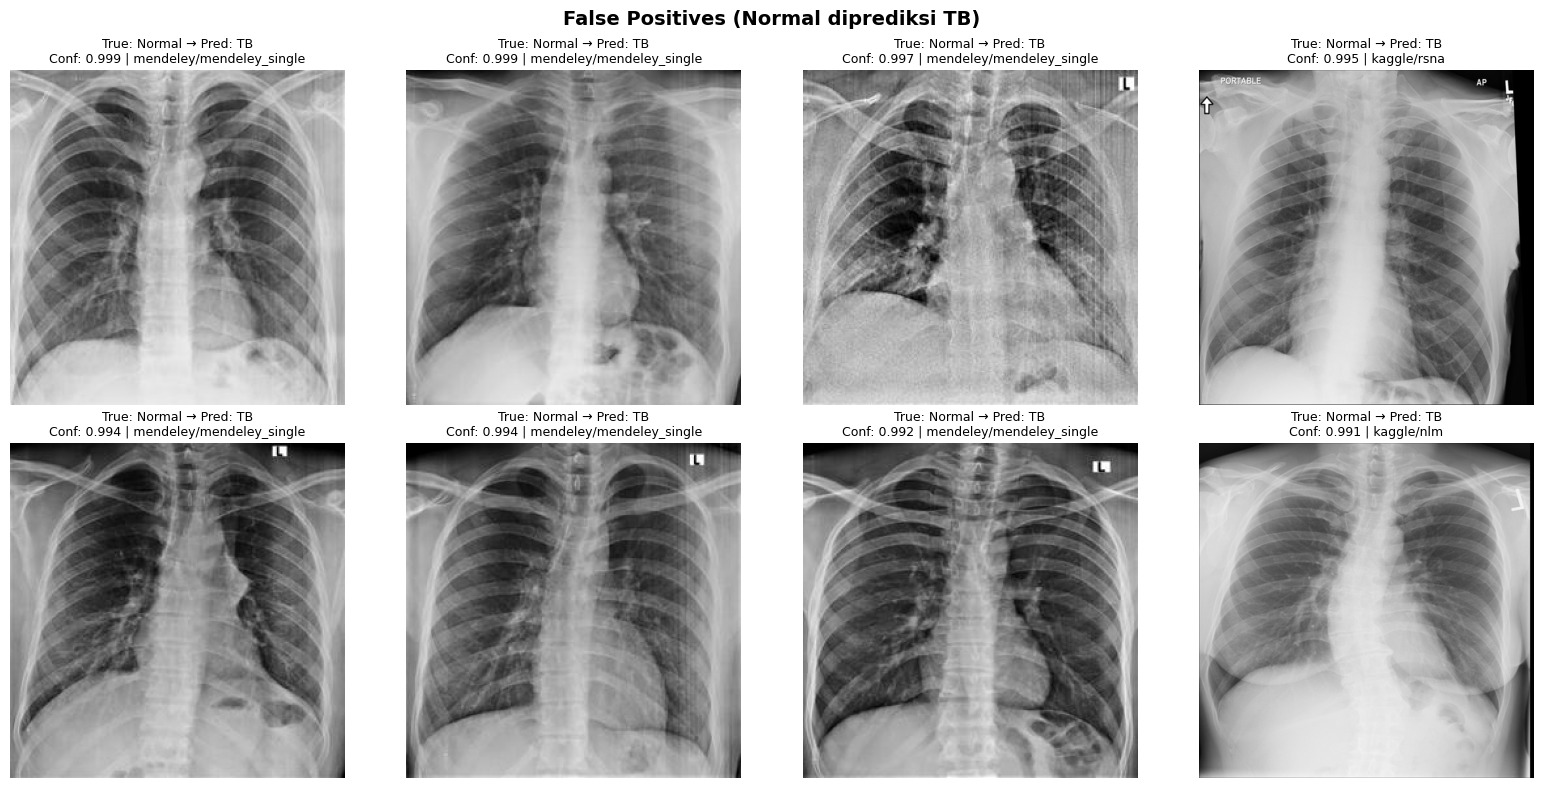

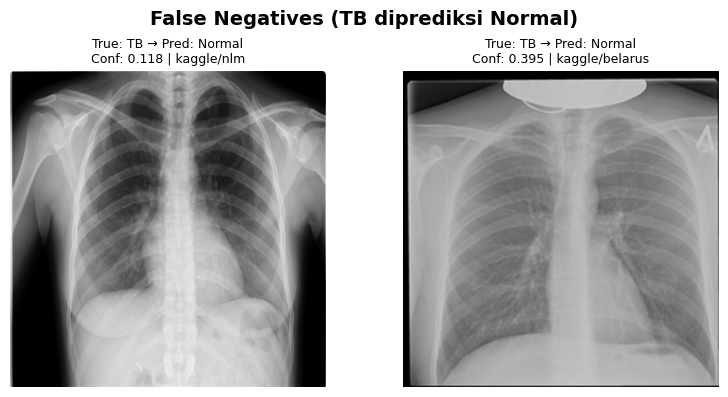


Distribusi misklasifikasi per source:

  FP (Normal→TB):
source    sub_source     
kaggle    nlm                 3
          rsna               23
mendeley  mendeley_single    31

  FN (TB→Normal):
source  sub_source
kaggle  belarus       1
        nlm           1


In [81]:
# ============================================================
# 10.2 Visualisasi Misclassified Samples
# ============================================================

# False Positives (Normal → predicted TB)
fp_mask = (df_test_eval['label_encoded'] == 0) & (df_test_eval['y_pred'] == 1)
# False Negatives (TB → predicted Normal)
fn_mask = (df_test_eval['label_encoded'] == 1) & (df_test_eval['y_pred'] == 0)

print(f'False Positives (Normal→TB): {fp_mask.sum()}')
print(f'False Negatives (TB→Normal): {fn_mask.sum()}')

def plot_misclassified(df_subset, title, n_show=8):
    """Plot grid of misclassified images."""
    n = min(n_show, len(df_subset))
    if n == 0:
        print(f'  Tidak ada {title}.')
        return
    
    samples = df_subset.head(n)
    cols = min(4, n)
    rows = (n + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    fig.suptitle(title, fontsize=14, fontweight='bold')
    
    if rows == 1 and cols == 1:
        axes = np.array([axes])
    axes = np.array(axes).flatten()
    
    for i, (_, row) in enumerate(samples.iterrows()):
        if i >= len(axes):
            break
        ax = axes[i]
        img = cv2.imread(row['filepath'])
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img)
        true_label = 'TB' if row['label_encoded'] == 1 else 'Normal'
        pred_label = 'TB' if row['y_pred'] == 1 else 'Normal'
        ax.set_title(f'True: {true_label} → Pred: {pred_label}\n'
                    f'Conf: {row["y_prob"]:.3f} | {row["source"]}/{row["sub_source"]}',
                    fontsize=9)
        ax.axis('off')
    
    # Hide empty axes
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
    
    plt.tight_layout()
    plt.show()

# Sort by confidence (most confident mistakes first)
fp_sorted = df_test_eval[fp_mask].sort_values('y_prob', ascending=False)
fn_sorted = df_test_eval[fn_mask].sort_values('y_prob', ascending=True)

plot_misclassified(fp_sorted, 'False Positives (Normal diprediksi TB)')
plot_misclassified(fn_sorted, 'False Negatives (TB diprediksi Normal)')

# Distribusi misklasifikasi per sumber
print('\nDistribusi misklasifikasi per source:')
for error_type, mask in [('FP (Normal→TB)', fp_mask), ('FN (TB→Normal)', fn_mask)]:
    print(f'\n  {error_type}:')
    if mask.sum() > 0:
        dist = df_test_eval[mask].groupby(['source', 'sub_source']).size()
        print(dist.to_string())
    else:
        print('    Tidak ada.')

In [82]:
# ============================================================
# 10.3 Grad-CAM Implementation
# ============================================================

def get_gradcam_heatmap(model, img_array, last_conv_layer_name=None):
    """
    Generate Grad-CAM heatmap for a given image.
    
    Args:
        model: Trained Keras model
        img_array: Preprocessed image array (1, H, W, 3)
        last_conv_layer_name: Name of last conv layer (auto-detected if None)
    
    Returns:
        heatmap: Grad-CAM heatmap (H, W)
    """
    # Auto-detect last conv layer if not specified
    if last_conv_layer_name is None:
        for layer in reversed(model.layers):
            if isinstance(layer, (tf.keras.layers.Conv2D,)):
                last_conv_layer_name = layer.name
                break
            # Also check inside the base model
            if hasattr(layer, 'layers'):
                for sub_layer in reversed(layer.layers):
                    if isinstance(sub_layer, (tf.keras.layers.Conv2D,)):
                        last_conv_layer_name = sub_layer.name
                        break
                if last_conv_layer_name:
                    break
    
    if last_conv_layer_name is None:
        print('Warning: Could not find last conv layer!')
        return np.zeros(IMG_SIZE)
    
    # Find the layer within the model or its submodels
    try:
        last_conv_layer = model.get_layer(last_conv_layer_name)
    except ValueError:
        # Try to find in sub-models
        for layer in model.layers:
            if hasattr(layer, 'get_layer'):
                try:
                    last_conv_layer = layer.get_layer(last_conv_layer_name)
                    # Create a model that outputs both the conv output and the final prediction
                    grad_model = Model(
                        inputs=model.input,
                        outputs=[layer.get_layer(last_conv_layer_name).output, model.output]
                    )
                    break
                except ValueError:
                    continue
        else:
            print(f'Warning: Layer {last_conv_layer_name} not found!')
            return np.zeros(IMG_SIZE)
    else:
        grad_model = Model(
            inputs=model.input,
            outputs=[last_conv_layer.output, model.output]
        )
    
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 0]  # For binary classification
    
    grads = tape.gradient(loss, conv_outputs)
    
    if grads is None:
        return np.zeros(IMG_SIZE)
    
    # Global average pooling of gradients
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    
    # Normalize
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    heatmap = heatmap.numpy()
    
    return heatmap


def overlay_gradcam(img_path, heatmap, alpha=0.4):
    """
    Overlay Grad-CAM heatmap on original image.
    
    Returns:
        superimposed_img: RGB image with heatmap overlay
    """
    img = cv2.imread(img_path)
    img = cv2.resize(img, IMG_SIZE)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Resize heatmap to image size
    heatmap_resized = cv2.resize(heatmap, IMG_SIZE)
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_colored = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    
    superimposed = np.uint8(heatmap_colored * alpha + img_rgb * (1 - alpha))
    
    return img_rgb, superimposed

print('Grad-CAM functions defined.')

Grad-CAM functions defined.


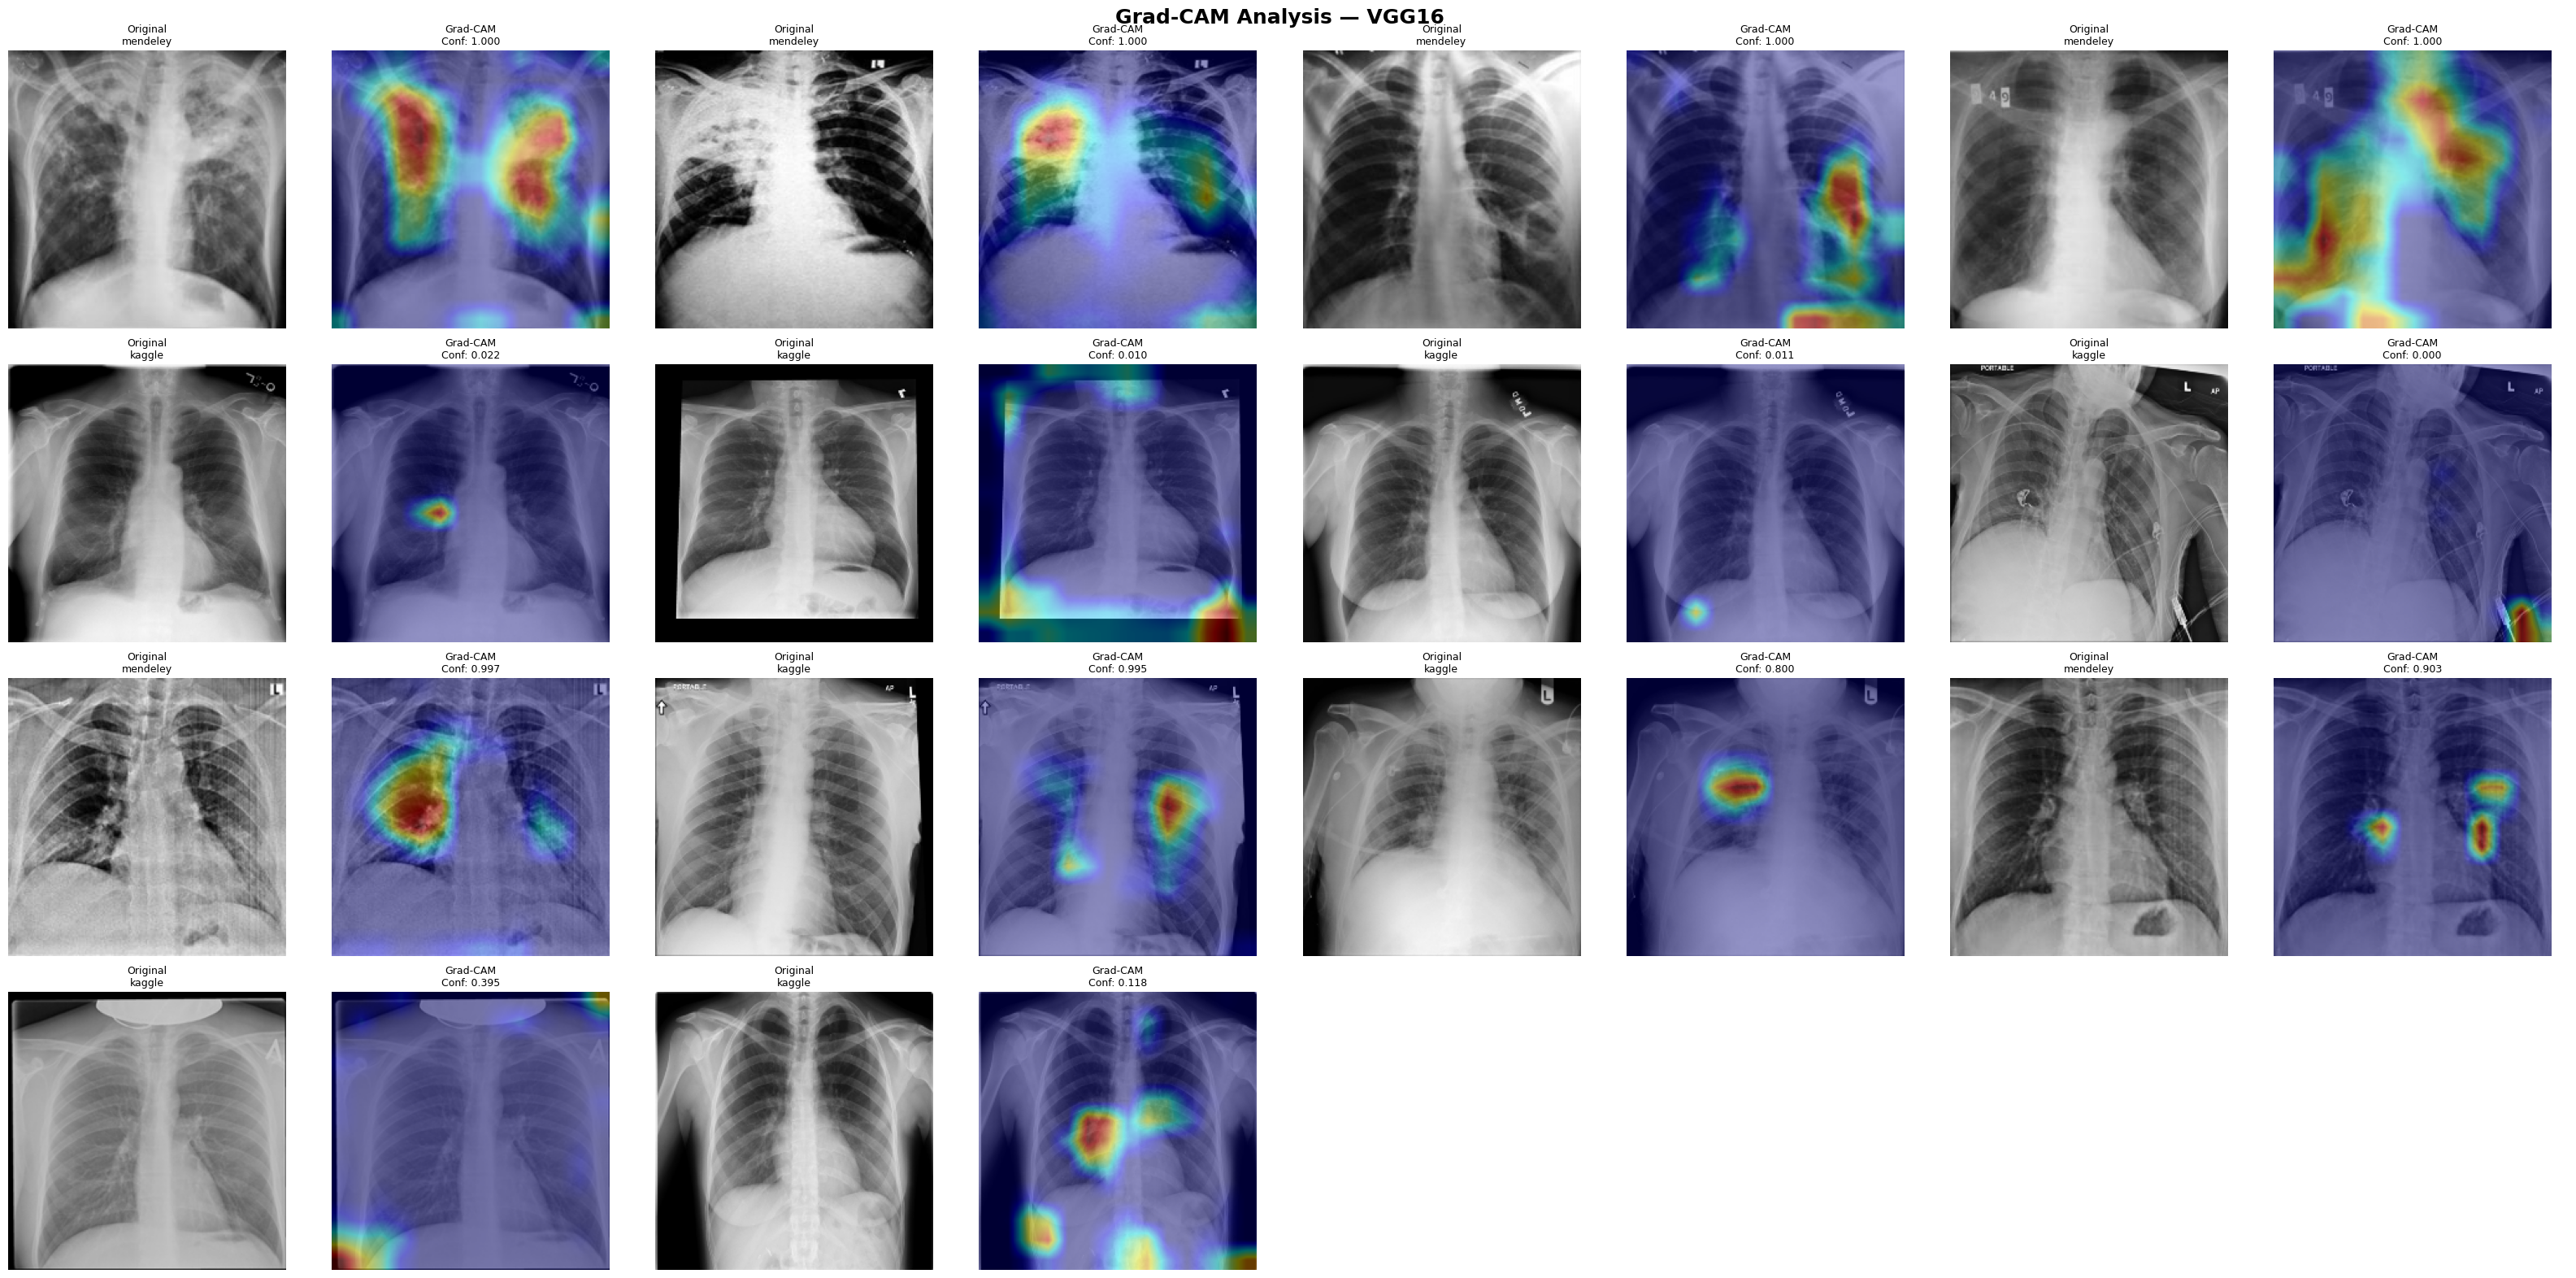


--- Interpretasi Grad-CAM ---
Area merah/kuning = fokus perhatian model (seharusnya area paru)
Jika model fokus pada tepi gambar, marker, atau teks → indikasi spurious correlation


In [83]:
# ============================================================
# 10.4 Grad-CAM Visualization
# ============================================================

best_model = all_models[best_arch]
best_preprocess = preprocess_fns[best_arch]

# Pilih sampel: TP, TN, FP, FN
tp_mask = (df_test_eval['label_encoded'] == 1) & (df_test_eval['y_pred'] == 1)
tn_mask = (df_test_eval['label_encoded'] == 0) & (df_test_eval['y_pred'] == 0)

sample_categories = [
    ('True Positive (TB→TB)', df_test_eval[tp_mask]),
    ('True Negative (Normal→Normal)', df_test_eval[tn_mask]),
    ('False Positive (Normal→TB)', df_test_eval[fp_mask]),
    ('False Negative (TB→Normal)', df_test_eval[fn_mask]),
]

n_samples_per_cat = 4

fig, axes = plt.subplots(len(sample_categories), n_samples_per_cat * 2,
                          figsize=(4 * n_samples_per_cat * 2, 4 * len(sample_categories)))
fig.suptitle(f'Grad-CAM Analysis — {best_arch}', fontsize=18, fontweight='bold')

for row_idx, (cat_name, cat_df) in enumerate(sample_categories):
    n = min(n_samples_per_cat, len(cat_df))
    if n == 0:
        for col in range(n_samples_per_cat * 2):
            axes[row_idx, col].text(0.5, 0.5, 'No samples', ha='center', va='center')
            axes[row_idx, col].axis('off')
        axes[row_idx, 0].set_ylabel(cat_name, fontsize=12, fontweight='bold')
        continue
    
    samples = cat_df.sample(n=n, random_state=RANDOM_SEED) if n < len(cat_df) else cat_df.head(n)
    
    for i, (_, row) in enumerate(samples.iterrows()):
        if i >= n_samples_per_cat:
            break
        
        # Load & preprocess image for model
        img = cv2.imread(row['filepath'])
        if img is None:
            continue
        img_resized = cv2.resize(img, IMG_SIZE)
        img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
        img_preprocessed = best_preprocess(
            np.expand_dims(img_rgb.astype(np.float32), axis=0)
        )
        
        # Generate Grad-CAM
        heatmap = get_gradcam_heatmap(best_model, img_preprocessed)
        _, superimposed = overlay_gradcam(row['filepath'], heatmap)
        
        # Plot original
        col_orig = i * 2
        col_cam = i * 2 + 1
        
        axes[row_idx, col_orig].imshow(img_rgb)
        axes[row_idx, col_orig].set_title(f'Original\n{row["source"]}', fontsize=9)
        axes[row_idx, col_orig].axis('off')
        
        axes[row_idx, col_cam].imshow(superimposed)
        axes[row_idx, col_cam].set_title(f'Grad-CAM\nConf: {row["y_prob"]:.3f}', fontsize=9)
        axes[row_idx, col_cam].axis('off')
    
    # Hide remaining axes
    for j in range(n * 2, n_samples_per_cat * 2):
        axes[row_idx, j].axis('off')
    
    axes[row_idx, 0].set_ylabel(cat_name, fontsize=11, fontweight='bold', rotation=90, labelpad=15)

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'gradcam_analysis.png'), dpi=150, bbox_inches='tight')
plt.show()

print('\n--- Interpretasi Grad-CAM ---')
print('Area merah/kuning = fokus perhatian model (seharusnya area paru)')
print('Jika model fokus pada tepi gambar, marker, atau teks → indikasi spurious correlation')

In [84]:
# ============================================================
# 10.5 Checkpoint: Temuan Domain Shift
# ============================================================

print('=' * 60)
print('CHECKPOINT: Error Analysis & Domain Shift')
print('=' * 60)

# Akurasi per source
print('\nAkurasi per sumber:')
for source in ['mendeley', 'kaggle']:
    mask = df_test_eval['source'] == source
    acc = df_test_eval.loc[mask, 'correct'].mean()
    print(f'  {source.capitalize()}: {acc:.4f} (n={mask.sum()})')

# Gap
acc_m = df_test_eval.loc[df_test_eval['source'] == 'mendeley', 'correct'].mean()
acc_k = df_test_eval.loc[df_test_eval['source'] == 'kaggle', 'correct'].mean()
gap = abs(acc_m - acc_k)
print(f'\nGap akurasi antar sumber: {gap:.4f}')
if gap > 0.10:
    print('⚠ Gap signifikan (>10%)! Model mungkin overfit ke satu sumber.')
elif gap > 0.05:
    print('⚠ Gap moderat (5-10%). Perlu perhatian tambahan.')
else:
    print('✓ Gap rendah (<5%). Model generalisasi cukup baik lintas domain.')

print('\n--- Ringkasan Error ---')
print(f'Total test samples: {len(df_test_eval)}')
print(f'False Positives: {fp_mask.sum()}')
print(f'False Negatives: {fn_mask.sum()} (KRITIS untuk skrining TB!)')
print('=' * 60)

CHECKPOINT: Error Analysis & Domain Shift

Akurasi per sumber:
  Mendeley: 0.9231 (n=403)
  Kaggle: 0.9425 (n=487)

Gap akurasi antar sumber: 0.0194
✓ Gap rendah (<5%). Model generalisasi cukup baik lintas domain.

--- Ringkasan Error ---
Total test samples: 890
False Positives: 57
False Negatives: 2 (KRITIS untuk skrining TB!)


---
## 11. Model Export & Kesimpulan

In [85]:
# ============================================================
# 11.1 Simpan Model & Artefak Final
# ============================================================

# Simpan model terbaik
best_model_path = str(OUTPUT_DIR / f'tb_cnn_{best_arch.lower()}_final.keras')
best_model.save(best_model_path)
print(f'✓ Model terbaik disimpan: {best_model_path}')

# Simpan training history
for arch_name in ARCHITECTURES:
    hist_path = str(OUTPUT_DIR / f'history_{arch_name}.json')
    # Convert numpy values to float for JSON serialization
    hist_serializable = {}
    for stage, h in all_histories[arch_name].items():
        hist_serializable[stage] = {
            k: [float(v) for v in vals] for k, vals in h.items()
        }
    with open(hist_path, 'w') as f:
        json.dump(hist_serializable, f, indent=2)
print(f'✓ Training histories disimpan')

# Simpan evaluation report
eval_report = {
    'best_architecture': best_arch,
    'optimal_threshold': float(optimal_threshold),
    'results_per_architecture': {
        k: {kk: float(vv) for kk, vv in v.items()}
        for k, v in eval_results.items()
    },
    'config': {
        'img_size': list(IMG_SIZE),
        'batch_size': BATCH_SIZE,
        'epochs_stage1': EPOCHS_STAGE1,
        'epochs_stage2': EPOCHS_STAGE2,
        'random_seed': RANDOM_SEED,
    }
}
with open(str(OUTPUT_DIR / 'evaluation_report.json'), 'w') as f:
    json.dump(eval_report, f, indent=2)
print(f'✓ Evaluation report disimpan')

# List semua file di outputs/
print(f'\nFile di {OUTPUT_DIR}:')
for fpath in sorted(OUTPUT_DIR.iterdir()):
    size_kb = fpath.stat().st_size / 1024
    print(f'  {fpath.name} ({size_kb:.1f} KB)')

✓ Model terbaik disimpan: c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\outputs\tb_cnn_vgg16_final.keras
✓ Training histories disimpan
✓ Evaluation report disimpan

File di c:\Users\Monk\Downloads\Deteksi Tuberkulosis (TB)\outputs:
  architecture_comparison.csv (0.6 KB)
  augmentation_samples.png (409.9 KB)
  augmentation_samples_basiccnn.png (27.9 KB)
  best_EfficientNetB0_final.keras (31466.9 KB)
  best_EfficientNetB0_stage1.keras (20898.8 KB)
  best_ResNet50_final.keras (212260.9 KB)
  best_ResNet50_stage1.keras (99342.7 KB)
  best_VGG16_final.keras (114828.8 KB)
  best_VGG16_stage1.keras (59516.3 KB)
  blur_detection.png (50.9 KB)
  class_distribution.png (77.5 KB)
  confusion_matrices.png (64.5 KB)
  evaluation_report.json (1.2 KB)
  gradcam_analysis.png (4629.7 KB)
  history_EfficientNetB0.json (4.7 KB)
  history_ResNet50.json (7.8 KB)
  history_VGG16.json (7.4 KB)
  learning_curves.png (266.4 KB)
  lung_segmentation_test_cv2.jpg (568.7 KB)
  metadata_clean.csv (1077.3 KB)
  

In [86]:
# ============================================================
# 11.2 Kesimpulan
# ============================================================

print('=' * 70)
print('KESIMPULAN')
print('=' * 70)
print()
print('1. RINGKASAN PERFORMA MODEL TERBAIK')
print('-' * 40)
best_metrics = eval_results[best_arch]
print(f'   Arsitektur     : {best_arch}')
print(f'   Accuracy       : {best_metrics["accuracy"]:.4f}')
print(f'   AUC-ROC        : {best_metrics["auc_roc"]:.4f}')
print(f'   F1-Score       : {best_metrics["f1"]:.4f}')
print(f'   TB Recall      : {best_metrics["recall_tb"]:.4f}')
print(f'   TB Precision   : {best_metrics["precision_tb"]:.4f}')
print(f'   Optimal Thresh : {optimal_threshold:.2f}')
print()
print('2. PERBANDINGAN ARSITEKTUR')
print('-' * 40)
for arch in ARCHITECTURES:
    m = eval_results[arch]
    star = ' ★' if arch == best_arch else ''
    print(f'   {arch:<18} AUC={m["auc_roc"]:.4f}  Recall_TB={m["recall_tb"]:.4f}  F1={m["f1"]:.4f}{star}')
print()
print('3. TEMUAN DOMAIN SHIFT')
print('-' * 40)
print(f'   Gap akurasi Mendeley vs Kaggle: {gap:.4f}')
print(f'   False Negatives (TB missed)   : {fn_mask.sum()}')
print(f'   False Positives               : {fp_mask.sum()}')
print()
print('4. BATASAN MODEL')
print('-' * 40)
print('   - Hanya 700 TB dari Kaggle (tanpa 2800 NIAID)')
print('   - Domain shift antara 2 sumber dataset yang berbeda')
print('   - Resolusi asli sangat berbeda (255×250 vs 512×512)')
print('   - Label Normal Kaggle dari RSNA (bukan eksplisit healthy)')
print()
print('5. REKOMENDASI LANGKAH SELANJUTNYA')
print('-' * 40)
print('   - Tambahkan data NIAID (2800 TB) jika agreement tersedia')
print('   - Eksplorasi ensemble dari multiple arsitektur')
print('   - Domain-adversarial training untuk mitigasi domain shift')
print('   - Hyperparameter tuning (learning rate, layer unfreeze, dll)')
print('   - Cross-validation untuk estimasi performa lebih robust')
print()
print('=' * 70)
print('END OF NOTEBOOK')
print('=' * 70)

KESIMPULAN

1. RINGKASAN PERFORMA MODEL TERBAIK
----------------------------------------
   Arsitektur     : VGG16
   Accuracy       : 0.9337
   AUC-ROC        : 0.9979
   F1-Score       : 0.9188
   TB Recall      : 0.9940
   TB Precision   : 0.8542
   Optimal Thresh : 0.98

2. PERBANDINGAN ARSITEKTUR
----------------------------------------
   EfficientNetB0     AUC=0.9926  Recall_TB=0.9732  F1=0.9689
   ResNet50           AUC=0.9973  Recall_TB=0.9851  F1=0.9750
   VGG16              AUC=0.9979  Recall_TB=0.9940  F1=0.9188 ★

3. TEMUAN DOMAIN SHIFT
----------------------------------------
   Gap akurasi Mendeley vs Kaggle: 0.0194
   False Negatives (TB missed)   : 2
   False Positives               : 57

4. BATASAN MODEL
----------------------------------------
   - Hanya 700 TB dari Kaggle (tanpa 2800 NIAID)
   - Domain shift antara 2 sumber dataset yang berbeda
   - Resolusi asli sangat berbeda (255×250 vs 512×512)
   - Label Normal Kaggle dari RSNA (bukan eksplisit healthy)

5. REK